# MIDTERM PROJECT EXPLANATION - PLANTS APP TO PREDICT WHETHER TRANSPLANTED PLANTS WILL SURVIVE

**INTRODUCTION:** \
Australia is acively engaged in trying to restore indigenous plant species populations. \
\
Plants that are threatened or endangered are expected to find it more difficulty to adapting to change and can struggle when moved from one location to another.  Research based upon this dataset has shown that when plants are translocated, the rate of species decline goes to about 45% which is a significant improvement over the baseline rate of species decline of 72%.  

This project evaluates translocation data to predict whether plants will survive.  It considers all available features, determines which ones may be viable, and then drops less useful features in the model tuning process.  Representative model features include:
 * research to identify factors that can improve translocation success
 * application of treatments to support the transplanted species
 * species
 * family
 * lifeform (tree, shrub, fern)
 * state (the Australian translocation destination state)
 * conservation status
 * watering
 * mulching
 * weeding
 * whether the translocation site has been burnt
 * protection from grazing animals
 * organization managing the translocation project

This project does several things we have not learned about in this course that have been built into the web service app `predict.py`.  Specifically, the web service app sanitizes the submitted data to improve resilience by discarding any features that are not used by the model and then adding placeholders for any required features that are missing. Since the raw data is very messy, the web service applies enrichment in an effort to standardize free text values. Only enriched data is passed to pydantic for content validation.  During model training, the code actually assess which features are not useful and automatically discards them before finalizing the model.  

**CITATION:** \
Doyle CA, Pellow BJ, Bell SAJ, Reynolds DM, Silcock JL, Commander LE and Ooi MKJ (2022) Threatened Plant Translocation for Mitigation: Improving Data Accessibility Using Existing Legislative Frameworks. An Australian Case Study. Front. Conserv. Sci. 2:789448. doi: 10.3389/fcosc.2021.789448

**REFERENCES:** \
  https://www.frontiersin.org/journals/conservation-science/articles/10.3389/fcosc.2021.789448/full \
  https://www.anpc.asn.au/australian-plant-translocation-database/ \
  https://www.spiffa.org.au/vulnerable-rare-or-threatened-species-conservation-status-codes.html \
  https://view.officeapps.live.com/op/view.aspx?src=https%3A%2F%2Fwww.anpc.asn.au%2Fwp-content%2Fuploads%2F2021%2F08%2FAustralian_plant_translocation_database_PUBLIC_2018.xlsx&wdOrigin=BROWSELINK
    

# 1.0 - LOAD PACKAGES

## 1.1 - LOAD PACKAGES AND GET DATA

In [1]:
# 0.1 - DATA PREP AND MATH LIBRARIES

# STANDARD LIBRARY UTILITIES
import json
import pickle
from   pathlib                    import Path
import re

# DATA HANDLING AND NUMERICAL CALCULATIONS
import pandas       as pd
import numpy        as np

# HTTP AND SCIENTIFIC STATS
import requests
from   scipy                      import stats

# PLOTTING
import seaborn      as sns
from   matplotlib                 import pyplot as plt
# JUPYTER MAGIC (PLOTTING)
%matplotlib inline

# SKLEARN MODEL SELECTION AND DATA SPLITTING 
from   sklearn.model_selection    import (
                                    GridSearchCV, 
                                    StratifiedKFold,
                                    train_test_split           # SPLIT THE DATASET
                                  )

# SKLEARN METRICS
from   sklearn.metrics            import (
                                    accuracy_score,
                                    classification_report,
                                    mean_squared_error,        # REGRESSION ACCURACY METRIC
                                    roc_auc_score,             # CLASSIFICATION ACCURACY METRIC
                                    root_mean_squared_error    # REGRESSION ACCURACY METRIC
                                  )

# SKLEARN PREPROCESSING AND FEATURE TRANSFORMATION
from   sklearn.preprocessing      import StandardScaler
from   sklearn.feature_extraction import DictVectorizer        # CONVERT DICTIONARY TO FEATURE MATRIX

# SKLEARN MODELS AND PIPELINES
from   sklearn.ensemble           import RandomForestRegressor # ENEMBLE LEANING
from   sklearn.linear_model       import LogisticRegression
from   sklearn.pipeline           import Pipeline
from   sklearn.tree               import (
                                    DecisionTreeClassifier,    # CLASSIFICATION PREDICTIONS 
                                    DecisionTreeRegressor,     # REGRESSION PREDICTIONS
                                    export_text                # 
                                  )

# SKLEARN MODEL INTERPRETATION
from   sklearn.inspection         import permutation_importance

# OTHER ML TOOLS
from   xgboost                    import XGBClassifier
import joblib


## 1.1 - GET DATA

# 2.0 - HELPER FUNCTIONS

## 2.1 - DATA PREPARATION

In [2]:
# CLEAN STRINGS 
def fn_clean_text(value):
    # ============================================================
    # DESCRIPTION: RECEIVE A STRING AND REMOVE UNWANTED CHARACTERS 
    # ============================================================
    # PACKAGE REQUIREMENTS:
    #  pandas
    # ============================================================
    # PARAMETER    DESCRIPTION
    # ------------------------------------------------------------
    #  value        STRING TO CLEAN 
    # ============================================================
    # ============================================================
    # SYNTAX 
    # ------------------------------------------------------------
    #   fn_clean_text(column)
    # ============================================================
    if not isinstance(value, str):
        return value

    value = value.lower()
    value = value.replace('%', '_pct_')
    value = re.sub(r'[\s()/\-]+', '_', value)  # spaces, slashes, parentheses, hyphens
    value = re.sub(r"""['"]""", '', value)     # remove quotes
    value = re.sub(r'[,;?]', '', value)        # remove punctuation
    return value

def drop_column(in_dataframe, in_columns):
    # ============================================================
    # DESCRIPTION: RETURN A COPY OF THE DATAFRAME WITH ONE OR MORE  
    #              FEATURES (SOLUMNS) REMOVED 
    # ============================================================
    # PACKAGE REQUIREMENTS:
    #  pandas
    # ============================================================
    # PARAMETER    DESCRIPTION
    # ------------------------------------------------------------
    #  df          'pandas' DATAFRAME 
    #  columns     EITHER A FEATURE NAME OR A LIST CONTAINING  
    #                FEATURE NAMES 
    # ============================================================
    # SYNTAX 
    # ------------------------------------------------------------
    #   df = drop_column(df, "lifeform")
    #   df = drop_column(df, ["lifeform", "second_gen"])
    # ============================================================
    if not isinstance(in_dataframe, pd.DataFrame):
        raise TypeError("'in_dataframe' must be a pandas DataFrame")

    if isinstance(in_columns, str):
        in_columns = [in_columns]
    elif not isinstance(in_columns, (list, tuple)):
        raise TypeError("'in_columns' must be a column name or a list/tuple of names")

    missing = [
        column for column in in_columns
        if column not in in_dataframe.columns
    ]
    if missing:
        raise KeyError(f"Feature(s) (Column(s)) not found:\r\n{missing}")

    return in_dataframe.drop(columns=list(in_columns))


## 2.2 - DATA REVIEW

In [3]:
def fn_view_col_value_status_table(in_data, in_df=None):
    # ============================================================
    # DESCRIPTION: CREATE A TABLE SHOWING HOW MANY ROWS IN A 
    #              FEATURE ARE MISSING VALUES
    # ============================================================
    # PACKAGE REQUIREMENTS:
    #  pandas
    # ============================================================
    # PARAMETER    DESCRIPTION
    # ------------------------------------------------------------
    #  data         'pandas' DATAFRAME OR FEATURE NAME
    # ============================================================
    # SYNTAX 
    # ------------------------------------------------------------
    #   fn_view_col_value_status_table(df)
    #   fn_view_col_value_status_table(df["second_gen"])
    #   fn_view_col_value_status_table("second_gen", in_df=df)
    # ============================================================
    if isinstance(in_data, str):
        if in_df is None:
            raise ValueError("Pass 'in_df' when in_data is a column name")
        if in_data not in in_df.columns:
            raise KeyError(f"Column not found: {in_data}")
        columns = [(in_data, in_df[in_data])]

    elif isinstance(in_data, pd.Series):
        columns = [(in_data.name or "value", in_data)]

    elif isinstance(in_data, pd.DataFrame):
        columns = list(in_data.items())

    else:
        raise TypeError(
            "'in_data' must be a feature (column) name, pandas Series, or pandas DataFrame"
        )

    print("=" * 80)
    print("NON_MISSING\tMISSING\t\t%_MISSING\tCOLUMN")
    print("=" * 80)

    for column_name, series in columns:
        missing = int(series.isna().sum())
        non_missing = int(series.notna().sum())
        percent_missing = missing / len(series) * 100 if len(series) else 0

        print(
            f"{non_missing}\t\t{missing}\t\t"
            f"{percent_missing:.2f}%\t\t{column_name}"
        )

    print("=" * 80)


def fn_view_column_value_counts(in_data, in_df=None):
    # ============================================================
    # DESCRIPTION: PRINT VALUE COUNTS AND PERCENTAGES FOR EACH 
    #              VALUE IN A 'pandas' SERIES OR DATAFRAME
    # ============================================================
    # PACKAGE REQUIREMENTS:
    #  pandas      import pandas as pd
    # ============================================================
    # PARAMETER    DESCRIPTION
    # ------------------------------------------------------------
    #  in_data     'pandas' DATAFRAME OR FEATURE NAME
    #  in_df       'pandas' DATAFRAME
    # ============================================================
    # SYNTAX 
    # ------------------------------------------------------------
    #   fn_view_column_value_counts("second_gen", in_df=df)
    #   fn_view_column_value_counts(df["second_gen"])
    #   fn_view_column_value_counts(df)
    # ============================================================
    if isinstance(in_data, str):
        if in_df is None:
            raise ValueError("Pass 'in_df' when 'in_data' is a Feature (column) name")
        if in_data not in in_df.columns:
            raise KeyError(f"Column not found: {in_data}")
        series_list = [(in_data, in_df[in_data])]

    elif isinstance(in_data, pd.Series):
        series_list = [(in_data.name or "value", in_data)]

    elif isinstance(in_data, pd.DataFrame):
        series_list = list(in_data.items())

    else:
        raise TypeError(
            "'in_data' must be a Feature (column) name, pandas Series, or pandas DataFrame"
        )

    for column_name, series in series_list:
        counts = series.value_counts(dropna=False)
        total = len(series)

        print(f"\n{column_name}")
        print("COUNT\t\tFREQUENCY\tVALUE")
        print("=" * 80)

        for value, count in counts.items():
            percent = count / total * 100 if total else 0
            print(f"{count}\t\t{percent:.2f}%\t\t{value}")


def fn_view_feature_data_quality(in_data, in_df=None):
    # ============================================================
    # DESCRIPTION: SHOW MISSING VALUE STATUS AND VALUE COUNTS FOR 
    #                A 'pandas' FEATURE (COLUMN), SERIES, OR 
    #                DATAFRAME 
    #              COMBINES THE OUTPUT FROMFUNCTIONS: 
    #              - fn_view_col_value_status_table(in_df, in_columns)
    #              - fn_view_column_value_counts(in_data, in_df=None)
    # ============================================================
    # PACKAGE REQUIREMENTS:
    #  pandas
    # ============================================================
    # PARAMETER    DESCRIPTION
    # ------------------------------------------------------------
    #  data         'pandas' DATAFRAME OR FEATURE NAME
    # ============================================================
    # ============================================================
    # SYNTAX 
    # ------------------------------------------------------------
    #   fn_view_feature_data_quality("second_gen", in_df=df)
    #   fn_view_feature_data_quality(df["second_gen"])
    #   fn_view_feature_data_quality(df)
    # ============================================================

    if isinstance(in_data, str):
        if in_df is None:
            raise ValueError("Pass 'in_df' when 'in_data' is a feature (column name)")

        fn_view_col_value_status_table(in_data, in_df=in_df)
        fn_view_column_value_counts(in_data, in_df=in_df)

    elif isinstance(in_data, (pd.Series, pd.DataFrame)):
        fn_view_col_value_status_table(in_data)
        fn_view_column_value_counts(in_data)

    else:
        raise TypeError(
            "'in_data' must be a feature (column) name, pandas Series, or pandas DataFrame"
        )


## 2.2 - EVALUATION

### 2.2.1 - REGRESSION EVALUATION

In [4]:
# RMSE IS IN 'sklearn'
#   from sklearn.metrics import root_mean_squared_errorp    # IMPORT FUNCTION
#
#   rmse = root_mean_squared_error(y_val, predictions)      # CALCULATE ACCURACY
#   print("Validation RMSE:", rmse)                         # PRINT ACCURACY

### 2.2.2 - CLASSIFICATION EVALUATION

In [5]:
# ROC-AUC
#   from sklearn.metrics import                             # IMPORT FUNCTION
#
#   y_prob = model.predict_proba(X_val)[:, 1]               # MAKE PREDICTION
#   auc = roc_auc_score(y_val, y_prob)                      # CALCULATE 'auc'
#   print("ROC-AUC:", auc)                                  # PRINT ACCURACY

# 3.0 - PREPARE DATA

## 3.1 - GET AND PREVIEW DATA

In [6]:
###########################################################################################
#   3.1.1 - GET DATA
###########################################################################################
data_path  = "C:/Users/duffl/anaconda3/_CT161_GitHub_Repos/ml-zoomcamp-homework/07_midterm_project_plants/original_working_files/data/Australian_plant_translocation_database_PUBLIC_2018(ALL_TRANSLOCATIONS).csv"
df         = pd.read_csv(data_path)

###########################################################################################
#   3.1.2 - CLEAN COLUMN NAMES AND RECORD VALUES
###########################################################################################
df.columns             = [fn_clean_text(column) for column in df.columns]
df                     = df.map(fn_clean_text)

# MANUALLY FIX COLUMN WITH PERIOD IN COLUMN NAME
df['habitat_condition'] = df['habitat_condition_e.g._highly_disturbed_small_remnant_large_remnant_']
df.drop(columns=['habitat_condition_e.g._highly_disturbed_small_remnant_large_remnant_'], inplace=True)

###########################################################################################
#   3.1.3 - PREVIEW NEW COLUMN NAMES 
###########################################################################################
fn_view_col_value_status_table(df)
#   fn_view_col_value_status_table(df)
    #   fn_view_col_value_status_table(df["second_gen"])
    #   fn_view_col_value_status_table("second_gen", in_df=df)

#   fn_view_column_value_counts("second_gen", in_df=df)
    #   fn_view_column_value_counts(df["second_gen"])
    #   fn_view_column_value_counts(df)

#   fn_view_feature_data_quality("second_gen", in_df=df)
    #   fn_view_feature_data_quality(df["second_gen"])
    #   fn_view_feature_data_quality(df)

###########################################################################################
#   3.1.4 - PREVIEW DATA VALUES 
###########################################################################################
df.head(20)

NON_MISSING	MISSING		%_MISSING	COLUMN
1182		0		0.00%		status_summary
1182		0		0.00%		translocation_number
1182		0		0.00%		treatment_number
321		861		72.84%		treatment_description
1182		0		0.00%		species
1182		0		0.00%		family
1182		0		0.00%		lifeform
1182		0		0.00%		state
1166		16		1.35%		conservation_status_epbc_
1156		26		2.20%		conservation_status_state_
1182		0		0.00%		latitude_decimal_degrees_
1182		0		0.00%		longitude_decimal_degrees_
1182		0		0.00%		bioregion
1182		0		0.00%		broad_habitat_group
1166		16		1.35%		habitat_description
871		311		26.31%		research_to_support_translocation_
1177		5		0.42%		mitigation_translocation
1182		0		0.00%		translocation_type
775		407		34.43%		start_month
1138		44		3.72%		start_year
892		290		24.53%		number_of_subsequent_plantings
91		1091		92.30%		number_of_seeds_direct_seeding_only_
1054		128		10.83%		number_of_individuals_planted_or_germinated_if_direct_seeding_total_
67		1115		94.33%		number_planted_notes
1115		67		5.67%		propagule_type_seed_s

,status_summary,translocation_number,treatment_number,treatment_description,species,family,lifeform,state,conservation_status_epbc_,conservation_status_state_,...,medium_term_success_population_persisting_at_secure_site_,long_term_success_self_sustaining_population_established_with_dynamics_comparable_to_natural_populations_,reasons_for_failure_or_sub_optimal_performance_or_success_if_known_,failure_factors_summary,success_factors_summary,notes,project_managed_by,contact_person_s,references,habitat_condition
0,incomplete_but_sufficient_for_analysis,10,1.0,NaN,abutilon_julianae,malvaceae,shrub,norfolk_island,cr,NaN,...,yes,yes,NaN,NaN,NaN,successful_part_of_restoration_planting_and_sp...,NaN,NaN,de_lange_p.j._&_b.g.murray_2003_._chromosome_n...,in_national_park_part_of_restoration_planting
1,incomplete_but_sufficient_for_analysis,11,1.0,NaN,abutilon_julianae,malvaceae,shrub,norfolk_island,cr,NaN,...,yes,yes,NaN,NaN,NaN,successful_part_of_restoration_planting_and_sp...,NaN,NaN,de_lange_p.j._&_b.g.murray_2003_._chromosome_n...,in_national_park_part_of_restoration_planting
2,finalised,854,1.0,propagule_type_seedlings_,acacia_aprica,fabaceae,shrub,wa,en,cr,...,NaN,NaN,NaN,NaN,NaN,NaN,dbca_science_and_dbca_dbca_district,leonie_monks,monks_l_and_coates_d_2002_the_translocation_of...,highly_disturbed_rehabilitated_gravel_pit_in_r...
3,finalised,854,2.0,propagule_type_seeds_,acacia_aprica,fabaceae,shrub,wa,en,cr,...,NaN,NaN,NaN,NaN,NaN,NaN,dbca_science_and_dbca_dbca_district,leonie_monks,monks_l_and_coates_d_2002_the_translocation_of...,highly_disturbed_rehabilitated_gravel_pit_in_r...
4,finalised,855,1.0,NaN,acacia_aprica,fabaceae,shrub,wa,en,cr,...,NaN,NaN,NaN,NaN,NaN,NaN,dbca_science_and_dbca_district,leonie_monks_rebecca_dillon,monks_l_and_coates_d_2002_the_translocation_of...,disturbed_old_farmland_amongst_tree_plantings_
5,finalised,262,1.0,NaN,acacia_attenuata,fabaceae,shrub,qld,vu,vu,...,yes,yes,implementation_of_fire_management_plan_will_en...,NaN,planting_technique_active_disturbance_manageme...,brownlie_et_al_2009_paper:_the_maintenance_of_...,NaN,heather_brownlie_peter_duforq_alison_shapcott,usc_inquiry_into_environmental_offsets_brownli...,highly_disturbed_translocated_community_remnant_
6,incomplete_but_sufficient_for_analysis,263,1.0,NaN,acacia_attenuata,fabaceae,shrub,qld,vu,vu,...,no_,no,planted_out_tube_stock_died_for_various_reason...,climate_dry__site_selection_lack_of_maintenance_,NaN,the_selected_site_was_not_ideal_but_was_the_on...,fraser_coast_regional_council,tina_raveneau,NaN,small_remnant
7,finalised,264,1.0,NaN,acacia_attenuata,fabaceae,shrub,qld,vu,vu,...,no,no,flooding_,climate_flooding__too_few_plants_to_bein_with,NaN,reason_for_translocation:_these_works_were_und...,department_of_transport_and_main_roads_opus_ve...,caroline_haskard_,haskard_c_2014_translocation_compliance_report...,disturbed_small_remnant
8,finalised,265,1.0,NaN,acacia_attenuata,fabaceae,shrub,qld,vu,vu,...,no,no,inappropriate_translocation_habitat,poor_site_selection_lack_of_maintenance,NaN,sippy_creek_revegetation_site_ex_situ_populati...,NaN,robert_lamont,brownlie_h._playford_j._wallace_h._shapcott_a....,NaN
9,finalised,856,1.0,NaN,acacia_awestoniana,fabaceae,shrub,wa,vu,cr,...,NaN,NaN,NaN,NaN,NaN,NaN,dbca_science_and_dbca_district,leonie_monks_rebecca_dillon,NaN,national_park


## 3.2 - FIRST PASS CLEANING

### 3.2.1 - DROP RECORDS MARKED AS UNSUITABLE FOR ANALYSIS

In [7]:
# datapoint = 
df.loc[10].to_dict()

{'status_summary': 'finalised',
 'translocation_number': 12,
 'treatment_number': 1.0,
 'treatment_description': 'propagule_type_whole_plants_',
 'species': 'acacia_bakeri',
 'family': 'fabaceae',
 'lifeform': 'tree',
 'state': 'nsw',
 'conservation_status_epbc_': nan,
 'conservation_status_state_': 'vu',
 'latitude_decimal_degrees_': '_28.5',
 'longitude_decimal_degrees_': '153.5',
 'bioregion': 'south_eastern_queensland',
 'broad_habitat_group': 'rainforest',
 'habitat_description': 'wet_sclerophyll_eucalypt_forest_and_rainforest_margins.',
 'research_to_support_translocation_': 'previous_translocation',
 'mitigation_translocation': 'y',
 'translocation_type': 'introduction',
 'start_month': 'may',
 'start_year': '2004',
 'number_of_subsequent_plantings': nan,
 'number_of_seeds_direct_seeding_only_': nan,
 'number_of_individuals_planted_or_germinated_if_direct_seeding_total_': '19',
 'number_planted_notes': nan,
 'propagule_type_seed_seedling_cutting_tissue_culture_whole_plants_etc_'

In [8]:
###########################################################################################
#   3.2.1 - DROP RECORDS DATASET CREATORS HAVE MARKED AS UNSUITABLE FOR ANALYSIS
###########################################################################################
exclude_status_summary = r'incomplete|unable_to_monitor|finalised '

df                     = df.loc[
                          ~df['status_summary'].str.contains(
                            exclude_status_summary, 
                            na=False
                          )
                        ].copy()
print('records dropped')


records dropped


### 3.2.2 - DROP FEATURES UNSUITABLE FOR ANALYSIS

In [9]:
###########################################################################################
#   1. - CRITERIA TO DROP FEATURES  
#        - CONTENT IS UNIQUE ACROSS ALL RECORDS 
#        - FEW RECORDS HAVE VALUES
#        - TOO MANY CATEGORIES AND CATEGORY LABELS CANNOT BE COLLAPSED INTO A NEW LABEL 
###########################################################################################
exclude_features_list  =    [
                                'status_summary',
                                'treatment_number',
                                'treatment_description', 
                                'species', 
                                'family',
                                'bioregion',
                                'conservation_status_state_',
                                'latitude_decimal_degrees_',
                                'longitude_decimal_degrees_',
                                'habitat_description',
                                'start_month',
                                'start_year',
                                'translocation_number',
                                'number_of_seeds_direct_seeding_only_',
                                'number_of_individuals_planted_or_germinated_if_direct_seeding_total_',
                                'number_planted_notes',
                                'watering_in_only', 
                                'watering_<6_months_', 
                                'watering_>6_months_or_in_dry_season_', 
                                'last_monitoring_date',
                                'number_of_subsequent_plantings',
                                'no_second_generation_plants',
                                'short_term_success__pct__of_plants_which_survived_first_year_', 
                                'medium_term_success_population_persisting_at_secure_site_',
                                'long_term_success_self_sustaining_population_established_with_dynamics_comparable_to_natural_populations_',
                                'reasons_for_failure_or_sub_optimal_performance_or_success_if_known_',
                                'failure_factors_summary',
                                'success_factors_summary',
                                'notes',
                                'project_managed_by',
                                'contact_person_s', 
                                'references'
                            ]

###########################################################################################
#   2. - REPORT ANY FEATURES THAT CAN NOT BE FOUND
###########################################################################################
missing                = [col for col in exclude_features_list if col not in df.columns]
print("Features to remove that were not found:\r\n", missing)
print()

###########################################################################################
#   3. - DROP FEATURES IN LIST
###########################################################################################
df                     = df.drop(columns=exclude_features_list, errors='ignore')

###########################################################################################
#   4. - REVIEW REMAININNG FEATURES
###########################################################################################
print("=" * 80)
print("===== REMAINING FEATURES =======================================================")
fn_view_col_value_status_table(df)
print("=" * 80)


Features to remove that were not found:
 ['no_second_generation_plants']

===== REMAINING FEATURES =======================================================
NON_MISSING	MISSING		%_MISSING	COLUMN
841		0		0.00%		lifeform
841		0		0.00%		state
830		11		1.31%		conservation_status_epbc_
841		0		0.00%		broad_habitat_group
665		176		20.93%		research_to_support_translocation_
841		0		0.00%		mitigation_translocation
841		0		0.00%		translocation_type
806		35		4.16%		propagule_type_seed_seedling_cutting_tissue_culture_whole_plants_etc_
692		149		17.72%		soil_preparation_y_n_
692		149		17.72%		pre_planting_burn_y_n_
681		160		19.02%		pre_planting_slashing_or_weeding_y_n_
690		151		17.95%		pre_site_preparation_all_
684		157		18.67%		herbivore_exclosure_fence_y_n_
684		157		18.67%		herbivore_exclosure_cages_y_n_
684		157		18.67%		tree_guards_y_n_
681		160		19.02%		grazing_protection_all_
691		150		17.84%		mulching_y_n_
694		147		17.48%		watering_all_
686		155		18.43%		burnt_0_unburnt_1_planned_2_wildfi

## 3.3 - DATA CLEANING

### 3.3.01 - FEATURE ENRICHMENT: 'treatment_number' ==> 'treatment'

### 3.3.02 - FEATURE ENRICHMENT: 'lifeform'

In [10]:
# PREVIEW RAW DATA VALUES 
source_column          = 'lifeform'
destination_column     = 'lifeform'

fn_view_feature_data_quality(df[source_column])

# CLEAN DATA  
dict_map               = {
                            'shrub': 'shrub',
                            'tree': 'tree',
                            'perennial_forb': 'perennial_forb',
                            'ground_orchid': 'ground_orchid',
                            'perennial_vine': 'perennial_vine',
                            'annual_forb': 'annual_forb',
                            'perennial_grass': 'perennial_grass',
                            'perennial_lily': 'perennial_lily',
                            'annual_grass': 'annual_grass',
                            'cycad': 'cycad',
                            'perennial_forb_fern_': 'perennial_forb_fern',
                            'perennial_sedge': 'perennial_sedge',
                            'perennnial_forb': 'perennnial_forb',
                            'perennial_sedge': 'perennial_sedge',
                            'perennnial_forb': 'perennnial_forb',
                            'orchid_epiphytic_': 'orchid_epiphytic',
                            'palm': 'palm',
                            'grass_tree': 'grass_tree',
                            'tree_mallee_': 'tree_mallee',
                            'fern': 'fern',
                            'epiphyte': 'epiphyte',
                            'annual_sedge': 'annual_sedge',
                            'tree_': 'tree',
                            'perennial_aquatic_forb': 'perennial_aquatic_forb',
                            'shrub_' : 'shrub'
                         }
df[destination_column]     = df[source_column].astype('string').str.strip().replace(dict_map).fillna('missing')

if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(df[destination_column])


NON_MISSING	MISSING		%_MISSING	COLUMN
841		0		0.00%		lifeform

lifeform
COUNT		FREQUENCY	VALUE
394		46.85%		shrub
141		16.77%		tree
95		11.30%		perennial_forb
69		8.20%		ground_orchid
35		4.16%		perennial_vine
26		3.09%		annual_forb
22		2.62%		annual_grass
20		2.38%		perennial_grass
8		0.95%		cycad
7		0.83%		perennial_lily
5		0.59%		perennial_forb_fern_
5		0.59%		perennnial_forb
2		0.24%		orchid_epiphytic_
2		0.24%		grass_tree
2		0.24%		tree_mallee_
2		0.24%		fern
2		0.24%		epiphyte
1		0.12%		annual_sedge
1		0.12%		palm
1		0.12%		perennial_aquatic_forb
1		0.12%		shrub_
NON_MISSING	MISSING		%_MISSING	COLUMN
841		0		0.00%		lifeform

lifeform
COUNT		FREQUENCY	VALUE
395		46.97%		shrub
141		16.77%		tree
95		11.30%		perennial_forb
69		8.20%		ground_orchid
35		4.16%		perennial_vine
26		3.09%		annual_forb
22		2.62%		annual_grass
20		2.38%		perennial_grass
8		0.95%		cycad
7		0.83%		perennial_lily
5		0.59%		perennial_forb_fern
5		0.59%		perennnial_forb
2		0.24%		grass_tree
2		0.24%		orchid_epiph

### 3.3.03 - FEATURE ENRICHMENT: 'state'

In [11]:
# PREVIEW RAW DATA VALUES 
source_column           = 'state' 
destination_column      = 'state' 

fn_view_feature_data_quality(df[source_column])

# CLEAN DATA  
# df[destination_column]  = df[source_column].copy()
df[destination_column]= df[source_column].str.strip().replace('qld_', 'qld')

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)
    
# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(df[destination_column])


NON_MISSING	MISSING		%_MISSING	COLUMN
841		0		0.00%		state

state
COUNT		FREQUENCY	VALUE
207		24.61%		nsw
196		23.31%		vic
186		22.12%		sa
133		15.81%		wa
91		10.82%		qld
20		2.38%		tas
6		0.71%		act
2		0.24%		qld_
NON_MISSING	MISSING		%_MISSING	COLUMN
841		0		0.00%		state

state
COUNT		FREQUENCY	VALUE
207		24.61%		nsw
196		23.31%		vic
186		22.12%		sa
133		15.81%		wa
93		11.06%		qld
20		2.38%		tas
6		0.71%		act


### 3.3.04 - FEATURE ENRICHMENT: 'conservation_status_epbc_'

In [12]:
# PREVIEW RAW DATA VALUES 
source_column           = 'conservation_status_epbc_' 
destination_column      = 'conservation_status' 

fn_view_feature_data_quality(df[source_column])

# CLEAN DATA                 
dict_map               = {
                            'en' : 'endangered',
                            'vu' : 'vulnerable',
                            'cr' : 'critically_endangered',
                            'vu' : 'vulnerable',
                            'vu_' : 'vulnerable',
                            'rotap_2rc_' : 'rare',
                            'not_listed_rotap_3rca_' : 'rare',
                            'not_listed_rotap_' : 'not_listed',
                            'ev' : 'extinct_in_wild',
                         }
df[destination_column] = df[source_column].astype('string').str.strip().replace(dict_map).fillna('missing') 

# DROP ORIGINAL COLUMN 
# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(df[destination_column])


NON_MISSING	MISSING		%_MISSING	COLUMN
830		11		1.31%		conservation_status_epbc_

conservation_status_epbc_
COUNT		FREQUENCY	VALUE
415		49.35%		en
175		20.81%		not_listed
150		17.84%		vu
66		7.85%		cr
11		1.31%		nan
10		1.19%		vu_
6		0.71%		rotap_2rc_
4		0.48%		not_listed_rotap_3rca_
3		0.36%		not_listed_rotap_
1		0.12%		ev
NON_MISSING	MISSING		%_MISSING	COLUMN
841		0		0.00%		conservation_status

conservation_status
COUNT		FREQUENCY	VALUE
415		49.35%		endangered
178		21.17%		not_listed
160		19.02%		vulnerable
66		7.85%		critically_endangered
11		1.31%		missing
10		1.19%		rare
1		0.12%		extinct_in_wild


### 3.3.05 - FEATURE ENRICHMENT: 'broad_habitat_group'

In [13]:
# PREVIEW RAW DATA VALUES 
source_column          = 'broad_habitat_group'
destination_column     = 'habitat'

fn_view_feature_data_quality(df[source_column])

# CLEAN DATA 
dict_map               = {
                            'rainforest': 'rainforest',
                            'southern_shrublands_heathlands_woodlands': 'southern_shrublands_heathlands_woodlands',
                            'southern_shrublands_heathlands_woodlands_': 'southern_shrublands_heathlands_woodlands',
                            'grassland': 'grassland',
                            'grassy_woodland': 'grassy_woodland',
                            'wetland': 'wetland',
                            'dry_sclerophyll': 'dry_sclerophyll',
                            'mallee': 'mallee',
                            'grassland_with_chenopods': 'grassland_with_chenopods',
                            'coastal_heath': 'coastal_heath',
                            'wet_sclerophyll': 'wet_sclerophyll',
                            'banded_ironstone': 'banded_ironstone',
                            'grassland_sub_tropical_': 'grassland_sub_tropical',
                            'montane': 'montane',
                            'other': 'other',
                            'coastal_shrubland': 'coastal_shrubland',
                            'semi_arid_woodland': 'semi_arid_woodland',
                            'wetland_floodplain_': 'wetland_floodplain',
                            'coastal_headland': 'coastal_headland',
                            'coastal_forest': 'coastal_forest',
                            'coastal_dunes': 'coastal_dunes',
                            'grassland_': 'grassland',
                            'grassland_lomandra_': 'grassland_lomandra',
                            'wetland_riparian_': 'wetland_riparian',
                       }
df[destination_column] = df[source_column].astype('string').str.strip().replace(dict_map).fillna('unk')

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(df[destination_column])


NON_MISSING	MISSING		%_MISSING	COLUMN
841		0		0.00%		broad_habitat_group

broad_habitat_group
COUNT		FREQUENCY	VALUE
164		19.50%		rainforest
135		16.05%		southern_shrublands_heathlands_woodlands
95		11.30%		southern_shrublands_heathlands_woodlands_
82		9.75%		grassland
47		5.59%		mallee
47		5.59%		grassy_woodland
42		4.99%		grassland_with_chenopods
38		4.52%		wetland
36		4.28%		coastal_heath
21		2.50%		dry_sclerophyll
21		2.50%		wet_sclerophyll
20		2.38%		grassland_sub_tropical_
18		2.14%		montane
16		1.90%		coastal_shrubland
11		1.31%		semi_arid_woodland
9		1.07%		other
8		0.95%		banded_ironstone
7		0.83%		coastal_forest
6		0.71%		wetland_floodplain_
6		0.71%		dry_rainforest
5		0.59%		coastal_dunes
2		0.24%		grassland_lomandra_
2		0.24%		wetland_riparian_
2		0.24%		grassland_
1		0.12%		coastal_headland
NON_MISSING	MISSING		%_MISSING	COLUMN
841		0		0.00%		habitat

habitat
COUNT		FREQUENCY	VALUE
230		27.35%		southern_shrublands_heathlands_woodlands
164		19.50%		rainforest
84		9.99%		gra

### 3.3.06 - FEATURE ENRICHMENT: 'research_to_support_translocation_'

In [14]:
# PREVIEW RAW DATA VALUES 
source_column          = 'research_to_support_translocation_'
destination_column     = 'research'

fn_view_feature_data_quality(df[source_column])

# CLEAN DATA 
is_empty               = df[source_column].isna() | df[source_column].astype('string').str.strip().eq('')
is_underscore          = df[source_column].astype('string').str.strip().eq('_')

df[destination_column] = 'yes'
df.loc[is_empty | is_underscore, destination_column] = 'no'

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(df[destination_column])


NON_MISSING	MISSING		%_MISSING	COLUMN
665		176		20.93%		research_to_support_translocation_

research_to_support_translocation_
COUNT		FREQUENCY	VALUE
197		23.42%		yes
176		20.93%		nan
78		9.27%		no
54		6.42%		low
45		5.35%		medium
28		3.33%		previous_translocation
27		3.21%		genetics_pollinator_studies
23		2.73%		genetics
18		2.14%		yes_experimental_planting_trials_+_genetics_+_field_based_cross_pollination_experiment_
18		2.14%		yes_genetics_
16		1.90%		yes_genetics_review_of_translocations_undertaken_to_date_long_term_monitoring_
15		1.78%		this_was_a_pasture_mgmt_experimental_translocation
13		1.55%		fertilizer_trial
11		1.31%		y
11		1.31%		experimental_translocation
8		0.95%		yes_
7		0.83%		genetics_translocation_experiment
6		0.71%		yes_propagation_field_trials_
6		0.71%		yes_preliminary_translocation_trials_to_understand_microsite_and_habitat_preferences_
6		0.71%		yes_genetics_pollination_
5		0.59%		high
4		0.48%		experimental_translocations_previously_undertaken._
4		0.48%		yes

### 3.3.07 - FEATURE ENRICHMENT: 'mitigation_translocation'

In [15]:
# PREVIEW RAW DATA VALUES 
source_column          = 'mitigation_translocation'
destination_column     = 'mitigation'

fn_view_feature_data_quality(df[source_column])

# CLEAN DATA 
df[destination_column] = df[source_column].astype('string').str[0]
dict_map               = {
                            'n' : 'no',
                            'y' : 'yes',
                            'u' : 'missing'
                          }
df[destination_column] = df[destination_column].astype('string').str.strip().replace(dict_map).fillna('missing')

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(df[destination_column])


NON_MISSING	MISSING		%_MISSING	COLUMN
841		0		0.00%		mitigation_translocation

mitigation_translocation
COUNT		FREQUENCY	VALUE
565		67.18%		n
275		32.70%		y
1		0.12%		y_seedlings_damaged_by_maintenance_work_in_the_area
NON_MISSING	MISSING		%_MISSING	COLUMN
841		0		0.00%		mitigation

mitigation
COUNT		FREQUENCY	VALUE
565		67.18%		no
276		32.82%		yes


### 3.3.08 - FEATURE REDUCTION: 'habitat_condition'

In [16]:
# PREVIEW RAW DATA VALUES 
source_column           = 'habitat_condition'
destination_column      = '-N/A-'

fn_view_feature_data_quality(df[source_column])

print("\r\n\r\nTOO MANY CATEGORIES AND NOT ENOUGH RECORDS WITHN EACH CATEGORY")

# DROP FEATURE
df = drop_column(in_dataframe=df, in_columns=source_column)

print(f"\r\n--- FEATURE ['{source_column}'] DROPPED ---")

NON_MISSING	MISSING		%_MISSING	COLUMN
838		3		0.36%		habitat_condition

habitat_condition
COUNT		FREQUENCY	VALUE
68		8.09%		large_remnant
57		6.78%		small_remnant
44		5.23%		cleared_paddock_surrounded_by_regrowth
37		4.40%		highly_disturbed_pasture_grazed
24		2.85%		disturbed
19		2.26%		nature_reserve
17		2.02%		remnant
15		1.78%		large_remnant_good_condition
14		1.66%		grader_scraped_former_agricultural_land_owned_by_natural_trust
13		1.55%		established_regrowth
13		1.55%		national_park
10		1.19%		old_farmland_nature_reserve_
10		1.19%		40ha_reserve_with_history_of_cultivation_last_cultivated_in_1960s_and_grazing_until_purchased_for_conservation_in_2001_now_a_degraded_native_pasture
10		1.19%		regrowth_disturbed
9		1.07%		2500ha_grassland_property
9		1.07%		conservation_park_good_condition_
8		0.95%		awc_reserve_fenced_from_feral_animals_and_rabbits
8		0.95%		medium_size_medium_quality_remnant
8		0.95%		revegetation_site
8		0.95%		large_remnant_in_good_condition_
7		0.83%		roadside_ve

### 3.3.09 - FEATURE ENRICHMENT: 'translocation_type'

In [17]:
# PREVIEW RAW DATA VALUES 
source_column          = 'translocation_type'
destination_column     = 'translocation'

fn_view_feature_data_quality(df[source_column])

# CLEAN DATA 
dict_map               = {
                            'introduction'               : 'introduction',
                            'augmentation'               : 'augmentation',
                            'augmentation_experimental_' : 'augmentation',
                            'introduction_'              : 'introduction',
                            'introduction_salvage_'      : 'introduction',
                            'introduction_experimental_' : 'introduction',
                            'introduction_seed_orchard_' : 'introduction',
                            'augmentation_salvage_'      : 'augmentation',
                            'restocking_of_original_introduction_above_' : 'reintroduction',
                            'reintroduction'             : 'reintroduction',
                            'introduction_reintroduction_to_riverland_' : 'introduction_reintroduction',
                            'restocking_of_above_'       : 'reintroduction',
                            'assisted_migration'         : 'introduction',
                            'introduction_augmentation_' : 'introduction_augmentation_',
                            'introduction_different_site_but_same_remnant_as_natural_population_' : 'introduction',
                          }
df[destination_column] = df[source_column].astype('string').str.strip().replace(dict_map).fillna('missing')

# DROP ORIGINAL COLUMN 
# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(df[destination_column])


NON_MISSING	MISSING		%_MISSING	COLUMN
841		0		0.00%		translocation_type

translocation_type
COUNT		FREQUENCY	VALUE
595		70.75%		introduction
117		13.91%		augmentation
30		3.57%		augmentation_experimental_
24		2.85%		introduction_
20		2.38%		introduction_salvage_
16		1.90%		introduction_experimental_
11		1.31%		introduction_seed_orchard_
7		0.83%		augmentation_salvage_
7		0.83%		restocking_of_original_introduction_above_
5		0.59%		reintroduction
2		0.24%		introduction_reintroduction_to_riverland_
2		0.24%		restocking_of_above_
2		0.24%		assisted_migration
2		0.24%		introduction_augmentation_
1		0.12%		introduction_different_site_but_same_remnant_as_natural_population_
NON_MISSING	MISSING		%_MISSING	COLUMN
841		0		0.00%		translocation

translocation
COUNT		FREQUENCY	VALUE
669		79.55%		introduction
154		18.31%		augmentation
14		1.66%		reintroduction
2		0.24%		introduction_reintroduction
2		0.24%		introduction_augmentation_


### 3.3.10 - FEATURE REDUCTION: 'propagule_type_seed_seedling_cutting_tissue_culture_whole_plants_etc_'

In [18]:
# PREVIEW RAW DATA VALUES 
source_column           = 'propagule_type_seed_seedling_cutting_tissue_culture_whole_plants_etc_'
destination_column      = '-N/A-'

fn_view_feature_data_quality(df[source_column])

print("\r\n\r\nTOO MANY CATEGORIES AND NOT ENOUGH RECORDS WITHN EACH CATEGORY")

# DROP FEATURE
df = drop_column(in_dataframe=df, in_columns=source_column)

print(f"\r\n--- FEATURE ['{source_column}'] DROPPED ---")




NON_MISSING	MISSING		%_MISSING	COLUMN
806		35		4.16%		propagule_type_seed_seedling_cutting_tissue_culture_whole_plants_etc_

propagule_type_seed_seedling_cutting_tissue_culture_whole_plants_etc_
COUNT		FREQUENCY	VALUE
242		28.78%		seedlings
94		11.18%		cuttings
81		9.63%		whole_plants
63		7.49%		seedling
49		5.83%		seed
35		4.16%		nan
29		3.45%		seedlings_and_cuttings
27		3.21%		cuttings_seedling
23		2.73%		cutting
22		2.62%		seed_hand_broadcast_
19		2.26%		whole_plant
16		1.90%		whole_plants_+_soil_including_seedbank_
11		1.31%		direct_seeding
9		1.07%		whole_plants_salvage_
9		1.07%		seedlings_whole_plants_and_tubers_grown_from_seed_using_local_fungus_
9		1.07%		seedlings_
6		0.71%		seed_
6		0.71%		propagated_seedlings
6		0.71%		soil_seedbank
5		0.59%		whole_plant_transplanting
5		0.59%		seed_seedlings
4		0.48%		propagated_rhizomes
4		0.48%		seed_sown_
3		0.36%		seedlings_cuttings_and_seed
3		0.36%		cuttings_grown_from_salvaged_material
3		0.36%		cuttings_propagated_from_salvaged_pla

### 3.3.11 - FEATURE ENRICHMENT: 'soil_preparation_y_n_'

In [19]:
# PREVIEW RAW DATA VALUES 
source_column           = 'soil_preparation_y_n_'
destination_column      = 'soil_prep'

fn_view_feature_data_quality(df[source_column])

# CLEAN DATA 
df[destination_column]  = df[source_column].astype('string').str[0]
dict_map                = {
                            'n' : 'no',
                            'y' : 'yes',
                            'u' : 'missing'
                          }
df[destination_column]  = df[destination_column].astype('string').str.strip().replace(dict_map).fillna('missing')

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(df[destination_column])


NON_MISSING	MISSING		%_MISSING	COLUMN
692		149		17.72%		soil_preparation_y_n_

soil_preparation_y_n_
COUNT		FREQUENCY	VALUE
464		55.17%		n
149		17.72%		nan
59		7.02%		y
57		6.78%		y_slow_release_fertilizer
18		2.14%		y_organic_fertilizer
13		1.55%		y_grader_scraping_to_5cm_
12		1.43%		y_minimal
11		1.31%		y_fertilizer
9		1.07%		y_water_crystals
5		0.59%		y_raked_
4		0.48%		y_ripped
4		0.48%		y_raked_surface_
4		0.48%		y_ripped_seasol_fungicide
3		0.36%		y_watered_in_with_seasol
3		0.36%		y_scraped_ripped_and_cleared_
3		0.36%		y_seasol
2		0.24%		y_ripping_
2		0.24%		y_soil_loosened_
2		0.24%		y_planting_protocols_for_macrozamia
2		0.24%		y_scraped_
2		0.24%		y_buried_rocks_
1		0.12%		y_rotary_hoe_
1		0.12%		y_liquid_seaweed_&_fish_emulsion
1		0.12%		y_mounted
1		0.12%		y_dilute_seasol
1		0.12%		y_seaweed_emulsion
1		0.12%		y_15g_organic_fertilizer_chicken_manure_
1		0.12%		y_15g_slow_release_fertilizer
1		0.12%		y_fertilizer_water_crystals
1		0.12%		y_cycad_protocol
1		0.12%		y_trenche

### 3.3.12 - FEATURE ENRICHMENT: 'pre_planting_burn_y_n_'

In [20]:
# PREVIEW RAW DATA VALUES 
source_column          = 'pre_planting_burn_y_n_'
destination_column     = 'pre_planting_burn'

fn_view_feature_data_quality(df[source_column])

# CLEAN DATA  
df[destination_column] = df[source_column].astype('string').str[0]
dict_map                = {
                            'n' : 'no',
                            'y' : 'yes', 
                            'u' : 'missing'
                          }
df[destination_column]  = df[destination_column].astype('string').str.strip().replace(dict_map).fillna('missing')

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(df[destination_column])

NON_MISSING	MISSING		%_MISSING	COLUMN
692		149		17.72%		pre_planting_burn_y_n_

pre_planting_burn_y_n_
COUNT		FREQUENCY	VALUE
667		79.31%		n
149		17.72%		nan
23		2.73%		y
1		0.12%		y_one_site_only_
1		0.12%		y_wildfire_burnt_part_of_site_
NON_MISSING	MISSING		%_MISSING	COLUMN
841		0		0.00%		pre_planting_burn

pre_planting_burn
COUNT		FREQUENCY	VALUE
667		79.31%		no
149		17.72%		missing
25		2.97%		yes


### 3.3.13 - FEATURE ENRICHMENT: 'pre_planting_slashing_or_weeding_y_n_'

In [21]:
# PREVIEW RAW DATA VALUES 
source_column          = 'pre_planting_slashing_or_weeding_y_n_'
destination_column     = 'pre_planting_slashing_or_weeding'

fn_view_feature_data_quality(df[source_column])

# CLEAN DATA  
df[destination_column] = df[source_column].astype('string').str[0]
dict_map               = {
                            'n' : 'no',
                            'y' : 'yes',
                            'u' : 'missing'
                         }
df[destination_column] = df[destination_column].astype('string').str.strip().replace(dict_map).fillna('missing')

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(df[destination_column])

NON_MISSING	MISSING		%_MISSING	COLUMN
681		160		19.02%		pre_planting_slashing_or_weeding_y_n_

pre_planting_slashing_or_weeding_y_n_
COUNT		FREQUENCY	VALUE
402		47.80%		n
246		29.25%		y
160		19.02%		nan
12		1.43%		y_minimal_hand_weed
5		0.59%		y_weeding
4		0.48%		y_weed_spraying_where_necessary_
3		0.36%		y_weeding_
2		0.24%		y_slashing_
2		0.24%		y_vegetation_removed_
1		0.12%		
1		0.12%		y_hand_weeding_
1		0.12%		y_slash_perennial_grasses_
1		0.12%		y_spraying_
1		0.12%		y_weed_spraying_
NON_MISSING	MISSING		%_MISSING	COLUMN
841		0		0.00%		pre_planting_slashing_or_weeding

pre_planting_slashing_or_weeding
COUNT		FREQUENCY	VALUE
402		47.80%		no
278		33.06%		yes
161		19.14%		missing


### 3.3.14 - FEATURE ENRICHMENT: 'pre_site_preparation_all_'

In [22]:
# PREVIEW RAW DATA VALUES 
source_column          = 'pre_site_preparation_all_'
destination_column     = 'pre_site_prep'

fn_view_feature_data_quality(df[source_column])

# CLEAN DATA  
dict_map               = {
                            '0.0' : 'no',
                            '1.0' : 'yes',
                            'u' : 'missing'
                          }
df[destination_column] = df[source_column].astype('string').str.strip().replace(dict_map).fillna('missing')

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(df[destination_column])

NON_MISSING	MISSING		%_MISSING	COLUMN
690		151		17.95%		pre_site_preparation_all_

pre_site_preparation_all_
COUNT		FREQUENCY	VALUE
363		43.16%		1.0
327		38.88%		0.0
151		17.95%		nan
NON_MISSING	MISSING		%_MISSING	COLUMN
841		0		0.00%		pre_site_prep

pre_site_prep
COUNT		FREQUENCY	VALUE
363		43.16%		yes
327		38.88%		no
151		17.95%		missing


### 3.3.15 - FEATURE ENRICHMENT: 'herbivore_exclosure_fence_y_n_'

In [23]:
# PREVIEW RAW DATA VALUES 
source_column          = 'herbivore_exclosure_fence_y_n_'
destination_column     = 'exclosure_fence'

fn_view_feature_data_quality(df[source_column])

# CLEAN DATA  
df[destination_column] = df[source_column].astype('string').str[0]
dict_map               = {
                            'n' : 'no',
                            'y' : 'yes',
                            'p' : 'yes'
                         }
df[destination_column] = df[destination_column].astype('string').str.strip().replace(dict_map).fillna('missing') 

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA  
fn_view_feature_data_quality(df[destination_column])

NON_MISSING	MISSING		%_MISSING	COLUMN
684		157		18.67%		herbivore_exclosure_fence_y_n_

herbivore_exclosure_fence_y_n_
COUNT		FREQUENCY	VALUE
424		50.42%		n
180		21.40%		y
157		18.67%		nan
24		2.85%		y_grazing_removed_from_property_
8		0.95%		y_sheep_and_cattle_excluded_hares_present_
6		0.71%		y_stock_and_rabbit_proof_
5		0.59%		y_stock_
4		0.48%		y_half_of_plots_
4		0.48%		y_rabbits_and_stock_excluded_
4		0.48%		
3		0.36%		pre_planting_rabbit_warren_fumigation
2		0.24%		y_different_treatments_
2		0.24%		y_rabbit_and_kangaroo
2		0.24%		y_some
2		0.24%		n_
1		0.12%		n_stock_fence_only_plants_not_really_grazed_
1		0.12%		y_domestic_stock_excluded_
1		0.12%		y_total_exclosure_
1		0.12%		y_roo_fenced_
1		0.12%		y_stock_+_rabbits_excluded_
1		0.12%		n_not_required_as_no_browsers_on_island_
1		0.12%		y_wallabies_and_hares_
1		0.12%		y_macropods_excluded_
1		0.12%		y_wallaby_exclosure_
1		0.12%		y_except_ducks!_
1		0.12%		y_stock_only_+_rabbit_and_hare_control_initially
1		0.12%		y_
1		0.12%

### 3.3.16 - FEATURE ENRICHMENT: 'herbivore_exclosure_cages_y_n_'

In [24]:
# PREVIEW RAW DATA VALUES 
source_column          = 'herbivore_exclosure_cages_y_n_'
destination_column     = 'exclosure_cage'

fn_view_feature_data_quality(df[source_column])

# CLEAN DATA  
df[destination_column] = df[source_column].astype('string').str[0]
dict_map               = {
                            'n' : 'no',
                            'y' : 'yes',
                            'u' : 'missing',
                         }
df[destination_column] = df[destination_column].astype('string').str.strip().replace(dict_map).fillna('missing') 

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(df[destination_column])

NON_MISSING	MISSING		%_MISSING	COLUMN
684		157		18.67%		herbivore_exclosure_cages_y_n_

herbivore_exclosure_cages_y_n_
COUNT		FREQUENCY	VALUE
507		60.29%		n
157		18.67%		nan
139		16.53%		y
20		2.38%		y_
4		0.48%		
4		0.48%		y_only_for_plants_surviving_after_year_6_
3		0.36%		y_plastic_mesh_guards_
3		0.36%		y_portion_caged_
2		0.24%		y_rabbits_
1		0.12%		y_possums_and_wallabies_
1		0.12%		y_some_plants_
NON_MISSING	MISSING		%_MISSING	COLUMN
841		0		0.00%		exclosure_cage

exclosure_cage
COUNT		FREQUENCY	VALUE
507		60.29%		no
173		20.57%		yes
161		19.14%		missing


### 3.3.17 - FEATURE ENRICHMENT: 'herbivore_protection_y_n_'

### 3.3.17 - FEATURE ENRICHMENT: 'tree_guards_y_n_'

In [25]:
# PREVIEW RAW DATA VALUES 
source_column          = 'tree_guards_y_n_'
destination_column     = 'tree_guard'

fn_view_feature_data_quality(df[source_column])

# CLEAN DATA  
df[destination_column] = df[source_column].astype('string').str[0]
dict_map               = {
                            'n' : 'no',
                            'y' : 'yes',
                            'u' : 'missing',
                         }
df[destination_column] = df[destination_column].astype('string').str.strip().replace(dict_map).fillna('missing') 

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(df[destination_column])


NON_MISSING	MISSING		%_MISSING	COLUMN
684		157		18.67%		tree_guards_y_n_

tree_guards_y_n_
COUNT		FREQUENCY	VALUE
629		74.79%		n
157		18.67%		nan
49		5.83%		y
1		0.12%		y_for_first_year_
1		0.12%		y_
1		0.12%		y_staked_for_stability
1		0.12%		y_hessian_barriers_for_shade
1		0.12%		y_hessian_barriers
1		0.12%		y_outside_of_fencing_guards_were_used_to_protect_plants_4_6_survived_
NON_MISSING	MISSING		%_MISSING	COLUMN
841		0		0.00%		tree_guard

tree_guard
COUNT		FREQUENCY	VALUE
629		74.79%		no
157		18.67%		missing
55		6.54%		yes


### 3.3.18 - FEATURE ENRICHMENT: 'grazing_protection_all_'

In [26]:
# PREVIEW RAW DATA VALUES 
source_column          = 'grazing_protection_all_'
destination_column     = 'grazing_protection'

fn_view_feature_data_quality(df[source_column])

# CLEAN DATA  
df[destination_column] = df[source_column].astype('string').str[0]
dict_map               = {
                            '0' : 'no',
                            '1' : 'yes',
                         }
df[destination_column] = df[destination_column].astype('string').str.strip().replace(dict_map).fillna('missing') 

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(df[destination_column])

NON_MISSING	MISSING		%_MISSING	COLUMN
681		160		19.02%		grazing_protection_all_

grazing_protection_all_
COUNT		FREQUENCY	VALUE
427		50.77%		1.0
254		30.20%		0.0
160		19.02%		nan
NON_MISSING	MISSING		%_MISSING	COLUMN
841		0		0.00%		grazing_protection

grazing_protection
COUNT		FREQUENCY	VALUE
427		50.77%		yes
254		30.20%		no
160		19.02%		missing


### 3.3.19 - FEATURE ENRICHMENT: 'mulching_y_n_'

In [27]:
# PREVIEW RAW DATA VALUES 
source_column          = 'mulching_y_n_'
destination_column     = 'mulch'

fn_view_feature_data_quality(df[source_column])

# CLEAN DATA  
df[destination_column] = df[source_column].astype('string').str[0]
dict_map               = {
                            'n' : 'no',
                            'y' : 'yes',
                         }
df[destination_column] = df[destination_column].astype('string').str.strip().replace(dict_map).fillna('missing') 

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(df[destination_column])

NON_MISSING	MISSING		%_MISSING	COLUMN
691		150		17.84%		mulching_y_n_

mulching_y_n_
COUNT		FREQUENCY	VALUE
642		76.34%		n
150		17.84%		nan
46		5.47%		y
2		0.24%		y_cane_mulch
1		0.12%		y_matting_
NON_MISSING	MISSING		%_MISSING	COLUMN
841		0		0.00%		mulch

mulch
COUNT		FREQUENCY	VALUE
642		76.34%		no
150		17.84%		missing
49		5.83%		yes


### 3.3.20 - FEATURE ENRICHMENT: 'watering_all_'

In [28]:
# PREVIEW RAW DATA VALUES 
source_column          = 'watering_all_'
destination_column     = 'watering'

fn_view_feature_data_quality(df[source_column])

# CLEAN DATA  
dict_map               = {
                            '0.0' : 'no',
                            '1.0' : 'yes',
                            'u'   : 'missing'
                          }
df[destination_column] = df[source_column].astype('string').str.strip().replace(dict_map).fillna('missing')

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(df[destination_column])

NON_MISSING	MISSING		%_MISSING	COLUMN
694		147		17.48%		watering_all_

watering_all_
COUNT		FREQUENCY	VALUE
421		50.06%		1.0
273		32.46%		0.0
147		17.48%		nan
NON_MISSING	MISSING		%_MISSING	COLUMN
841		0		0.00%		watering

watering
COUNT		FREQUENCY	VALUE
421		50.06%		yes
273		32.46%		no
147		17.48%		missing


### 3.3.21 - FEATURE ENRICHMENT: 'burnt_0_unburnt_1_planned_2_wildfire_'

In [29]:
# PREVIEW RAW DATA VALUES 
source_column          = 'burnt_0_unburnt_1_planned_2_wildfire_'
destination_column     = 'burnt'

fn_view_feature_data_quality(df[source_column])

# CLEAN DATA  
dict_map               = {
                            '0'   : 'unburnt',
                            '1'   : 'planned',
                            '2'   : 'wildfire',
                            '1_2' : 'planned_wildfire',
                         }
df[destination_column] = df[source_column].astype('string').str.strip().replace(dict_map).fillna('missing')

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(df[destination_column])

NON_MISSING	MISSING		%_MISSING	COLUMN
686		155		18.43%		burnt_0_unburnt_1_planned_2_wildfire_

burnt_0_unburnt_1_planned_2_wildfire_
COUNT		FREQUENCY	VALUE
608		72.29%		0
155		18.43%		nan
66		7.85%		1
8		0.95%		2
4		0.48%		1_2
NON_MISSING	MISSING		%_MISSING	COLUMN
841		0		0.00%		burnt

burnt
COUNT		FREQUENCY	VALUE
608		72.29%		unburnt
155		18.43%		missing
66		7.85%		planned
8		0.95%		wildfire
4		0.48%		planned_wildfire


### 3.3.22 - FEATURE ENRICHMENT: 'weeding_includes_exotic_and_native_competitors_number_of_times_or_y_n_'

In [30]:
# PREVIEW RAW DATA VALUES 
source_column          = 'weeding_includes_exotic_and_native_competitors_number_of_times_or_y_n_'
destination_column     = 'weeding'

print('#####  RAW  #####')
fn_view_feature_data_quality(df[source_column])

# CLEAN DATA  
df[destination_column] = df[source_column].astype('string').str.strip().str[0]
dict_map               = {
                            'n'   : 'no',
                            'y'   : 'yes',
                            '0'   : 'yes',
                            '1'   : 'yes',
                            '2'   : 'yes',
                            '3'   : 'yes',
                            '4'   : 'yes',
                            '5'   : 'yes',
                            '6'   : 'yes',
                            '7'   : 'yes',
                            '8'   : 'yes',
                            '9'   : 'yes',
                            'a'   : 'yes',
                            'c'   : 'yes',
                            'o'   : 'yes',
                            'r'   : 'yes',
                            't'   : 'yes',
                            'w'   : 'yes',
                            'u'   : 'missing'
                         }
df[destination_column] = df[destination_column].astype('string').replace(dict_map).fillna('missing')

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
print('##### CLEANED #####')
fn_view_feature_data_quality(df[destination_column])

#####  RAW  #####
NON_MISSING	MISSING		%_MISSING	COLUMN
676		165		19.62%		weeding_includes_exotic_and_native_competitors_number_of_times_or_y_n_

weeding_includes_exotic_and_native_competitors_number_of_times_or_y_n_
COUNT		FREQUENCY	VALUE
281		33.41%		n
165		19.62%		nan
122		14.51%		y
36		4.28%		4_years
31		3.69%		not_detailed
17		2.02%		3+
15		1.78%		y_slashed_
13		1.55%		not_documented
13		1.55%		3
11		1.31%		0.00
10		1.19%		y_periodically_by_hand_
10		1.19%		y:_2_3_yr_within_cages
9		1.07%		
8		0.95%		regular
7		0.83%		2
6		0.71%		3x_year
5		0.59%		1
5		0.59%		y_twice_
4		0.48%		y_regular_
4		0.48%		annually
3		0.36%		18.00
3		0.36%		12.00
2		0.24%		y_occasional_
2		0.24%		ongoing
2		0.24%		3.00
2		0.24%		c.2x_year_with_concerted_effort_following_burning_
2		0.24%		y_spring_1987_capeweed_only_targeted_
2		0.24%		y_spraying_+_hand_weeding_2yrs_
2		0.24%		12_weeks
2		0.24%		c.15_quarterly_with_extra_attention_post_burn_
2		0.24%		y:_2_3_yr_within_imm._vicinity_of_plants
2		0.24%		y_6

### 3.3.23 - FEATURE ENRICHMENT: 'plants_surviving__pct__'

In [31]:
source_column          = 'plants_surviving__pct__'
destination_column     = 'plants_surviving_pct'
# destination_column_cnt = 'plants_surviving_cnt'

fn_view_feature_data_quality(df[source_column])

##########################################################################################
# NORMALIZE PERCENTAGE OF PLANTS THAT SURVIVED TRANSPLANTING
###########################################################################################
source = df[source_column].astype('string').str.strip()

dict_map = {
    '<NA>'                          : '0.00',
    '<na>'                          : '0.00',
    '??'                            : '0.00',
    '#div/0!'                       : '0.00',
    '#ref!'                         : '0.00',
    '#value!'                       : '0.00',
    'apr_00'                        : '0.00',
    'n_a_annual_'                   : '0.00',
    'n_a_for_annual_species'        : '0.00',
    'n_a_annual_plant_'             : '0.00',
    'n_a_direct_seeding_'           : '0.00',
    'n_a_short_lived_'              : '0.00',
    'Not monitored yet'             : '0.00',
    'unknown_probably_0_'           : '0.00',
    '0_but_substantial_recruitment_': '0.00',
    '<5'                            : '5.00',
    '<10'                           : '10.00',
    '>10'                           : '10.00',
    '>10_pct_'                      : '10.00',
    '16_pct_'                       : '16.00',
    '4_pct_'                        : '4.00', 
    '11_pct_'                       : '11.00',
    'c20'                           : '20.00',
    'c25_pct_'                      : '25.00',
    '17_pct_'                       : '17.00',
    '<20'                           : '20.00',
    'c.20'                          : '20.00',
    '>25'                           : '25.00',
    '>25_pct_'                      : '25.00',
    'c.25'                          : '25.00',
    '20-40_pct_'                    : '30.00',
    '20-40'                         : '30.00',
    'c.25'                          : '25.00',
    '29_pct_'                       : '29.00',
    '~30'                           : '30.00',
    '>30'                           : '30.00',
    '>33'                           : '33.00',
    '~40'                           : '40.00',
    '>40'                           : '40.00',
    '<50?'                          : '50.00',
    '<50_pct_'                      : '50.00',
    '<50_pct_?'                     : '50.00',
    '<50?'                          : '50.00',
    '50_pct_'                       : '50.00',
    '~50'                           : '50.00',
    '>50_pct_'                      : '50.00',
    '>50'                           : '50.00',
    '>50_pct_'                      : '50.00',
    '52_pct_'                       : '52.00',
    '60_pct_'                       : '60.00',
    '69_pct_'                       : '69.00',
    'unknown_but_probably_>75_pct_' : '75.00',
    '77_pct_'                       : '77.00',
    '80_pct_'                       : '80.0',
    '80_pct__across_all_sites_and_treatments_'  : '80.00',
    '80_pct_ (across all sites and treatments)' : '80.00',
    '83_pct_'                       : '83.00',
    '85_pct_'                       : '85.0',
    '>90'                           : '90.00',
    '>95'                           : '95.00',
    '>95_pct_'                      : '95.00',
    '100_pct_'                      : '100.00',
    '>100_with_recruitment_'        : '0.00',
    'good'                          : '0.00',
    'unknown'                       : '0.00',
    'Unknown'                       : '0.00',
    'unknown_number_germinating_not_documented_' : '0.00',
    'unknown_how_many_were_planted_in_total'     : '0.00',
    'unknown_number_of_germinants_not_counted_'  : '0.00',
    'too_early'                     : '0.00',
    'plants_in_the_ground_for_<_12_months'       : '0.00',
    '<12_months_since_planting'     : '0.00',
    '<_12_mnths_since_translocation': '0.00',
    '<12_months_elapsed'            : '0.00',
    '_pct_'                         : '0.00',
}

cleaned = (
    source.replace(dict_map)
          .str.replace('%', '', regex=False)
          .str.strip()
)

parts = cleaned.str.split(':',n=1)

# CREATE NEW COLUMN
# df[destination_column] = (
#    pd.to_numeric(parts.str[0], errors='coerce')
#      .fillna(0.0)
# )

surviving                  = pd.to_numeric(parts.str[0].str.strip(), errors="coerce")
surviving_mean             = surviving.mean()
surviving                  = surviving.fillna(surviving_mean) 

count                      = pd.to_numeric(parts.str[1].str.strip(), errors="coerce") # .fillna(0.0) 
count_mean                 = count.mean()
count                      = count.fillna(count_mean) 

# STORE AS NUMERIC
df[destination_column] = surviving.astype("Float64")
# df["plants_surviving_cnt"] = count.astype("Int32")

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_column_value_counts(df[destination_column])


NON_MISSING	MISSING		%_MISSING	COLUMN
676		165		19.62%		plants_surviving__pct__

plants_surviving__pct__
COUNT		FREQUENCY	VALUE
165		19.62%		nan
126		14.98%		0.00
79		9.39%		100.00
15		1.78%		<12_months_elapsed
13		1.55%		50.00
13		1.55%		too_early
12		1.43%		n_a_short_lived_
11		1.31%		unknown_number_of_germinants_not_counted_
9		1.07%		25.00
9		1.07%		80.00
8		0.95%		75.00
7		0.83%		
6		0.71%		4.00
6		0.71%		60.00
6		0.71%		40.00
6		0.71%		42.00
6		0.71%		31.00
5		0.59%		38.00
5		0.59%		0
5		0.59%		10.00
5		0.59%		20.00
5		0.59%		78.00
4		0.48%		88.00
4		0.48%		18.00
4		0.48%		#ref!
4		0.48%		90.00
4		0.48%		n_a_annual_plant_
4		0.48%		unknown
4		0.48%		n_a_for_annual_species
4		0.48%		59.00
4		0.48%		33.00
4		0.48%		67.00
4		0.48%		>50_pct_
4		0.48%		85_pct_
4		0.48%		n_a_annual_
4		0.48%		50
4		0.48%		45.00
3		0.36%		6.70
3		0.36%		48.00
3		0.36%		2.00
3		0.36%		64.00
3		0.36%		70.00
3		0.36%		86.00
3		0.36%		3.00
3		0.36%		>50
3		0.36%		15.00
3		0.36%		<_12_mnths_since_translocati

### 3.3.24 - FEATURE ENRICHMENT: 'reproductive_flowering_fruiting_y_n_'

In [32]:
# PREVIEW RAW DATA VALUES 
source_column          = 'reproductive_flowering_fruiting_y_n_'
destination_column     = 'flowering_fruiting'

fn_view_feature_data_quality(df[source_column])

# CLEAN DATA  
df[destination_column] = df[source_column].astype('string').str[0]
dict_map               = {
                            'y'   : 'yes',
                            'n'   : 'no',
                            't'   : 'missing',
                            'p'   : 'missing',
                            '<'   : 'missing',
                            'u'   : 'missing',
                            'unk' : 'missing'
                         }
df[destination_column] = df[destination_column].astype('string').str.strip().replace(dict_map).fillna('missing')

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(df[destination_column])

NON_MISSING	MISSING		%_MISSING	COLUMN
639		202		24.02%		reproductive_flowering_fruiting_y_n_

reproductive_flowering_fruiting_y_n_
COUNT		FREQUENCY	VALUE
322		38.29%		y
240		28.54%		n
202		24.02%		nan
16		1.90%		yes
14		1.66%		too_soon
7		0.83%		
7		0.83%		unknown
7		0.83%		<12_months_elapsed
3		0.36%		n_
3		0.36%		<12_months_since_planting
3		0.36%		not_recorded
3		0.36%		y_
2		0.24%		y_flowered_
2		0.24%		y_89_pct__flowered_
2		0.24%		too_early
2		0.24%		no
1		0.12%		plants_in_the_ground_for_<_12_months
1		0.12%		yes_but_<10_pct__
1		0.12%		y_65_pct__flowered_
1		0.12%		not_documented
1		0.12%		y_a_few_flowered_then_withered_
1		0.12%		n_minimal_
NON_MISSING	MISSING		%_MISSING	COLUMN
841		0		0.00%		flowering_fruiting

flowering_fruiting
COUNT		FREQUENCY	VALUE
348		41.38%		yes
250		29.73%		no
243		28.89%		missing


### 3.3.25 - FEATURE ENRICHMENT: 'second_generation_y_n_'

In [33]:
# PREVIEW RAW DATA VALUES 
source_column          = 'second_generation_y_n_'
destination_column     = 'second_gen'

fn_view_feature_data_quality(df[source_column])

# CLEAN DATA  
df[destination_column] = df[source_column].astype('string').str[0:3]
dict_map               = {
                            'y'   : 'yes',
                            'y_'  : 'yes',
                            'yes' : 'yes',
                            'y_4' : 'yes',
                            'y_f' : 'yes',
                            'y_i' : 'yes',
                            'y_r' : 'yes',
                            'y_v' : 'yes',
                            'n'   : 'no', 
                            'n_'  : 'no',  
                            '0'   : 'no', 
                            '0.0' : 'no', 
                            'too' : 'too_soon',
                            'pla' : 'too_soon',
                            '<12' : 'too_soon',
                            ''    : 'missing',
                            'not' : 'missing',
                            'u'   : 'missing',
                            'unk' : 'missing'
                         }
df[destination_column] = df[destination_column].astype('string').str.strip().replace(dict_map).fillna('missing')

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(df[destination_column])


NON_MISSING	MISSING		%_MISSING	COLUMN
682		159		18.91%		second_generation_y_n_

second_generation_y_n_
COUNT		FREQUENCY	VALUE
434		51.61%		n
159		18.91%		nan
114		13.56%		y
50		5.95%		too_soon
26		3.09%		too_early
20		2.38%		no
14		1.66%		y_vegetative_
3		0.36%		
2		0.24%		y_
2		0.24%		unknown
2		0.24%		<12_months_elapsed
2		0.24%		not_assessed
2		0.24%		0
1		0.12%		plants_in_the_ground_for_<_12_months
1		0.12%		y_runners
1		0.12%		unknown_probably_not_
1		0.12%		not_monitored_in_2015
1		0.12%		yes
1		0.12%		y_4_seedlings_from_seed_in_soil_plug_moved_with_plant_
1		0.12%		not_documented
1		0.12%		y_from_seed_stored_in_soil_moved_with_plants_not_from_translocated_plants_
1		0.12%		y_in_soil_plug_
1		0.12%		0.00
1		0.12%		n_
NON_MISSING	MISSING		%_MISSING	COLUMN
841		0		0.00%		second_gen

second_gen
COUNT		FREQUENCY	VALUE
458		54.46%		no
169		20.10%		missing
135		16.05%		yes
79		9.39%		too_soon


### 3.3.27 - FEATURE ENRICHMENT: 'no.plants_surviving_y_n'

In [34]:
# PREVIEW RAW DATA VALUES 
source_column           = 'number_of_plants_surviving' # 'no.plants_surviving_y_n' 
destination_column      = 'plants_surviving'

fn_view_feature_data_quality(df[source_column])

# CLEAN DATA  
dict_map                = {
                            "na": "",
                            "+": "999",
                            "<12_months_elapsed": "999",
                            ">100": "999",
                            "n_a_short_lived_": "999",
                            "34_30_just_planted_july2017_": "999",
                            "good_numbers_not_counted_": "999",
                            "<12_months_since_planting": "999",
                            "<_12_mnths_since_translocation": "999",
                            "present": "999",
                            "40_40_just_planted_july2017_": "999",
                            ">20": "999",
                            "not_monitored_yet": "",
                            "not_detailed": "999",
                            ">50": "999",
                            "19_+_12_planted_in_july_2016": "999",
                            "105_+_suckers": "999",
                            "17_+_suckers": "999",
                            "2_+_suckers": "999",
                            "3_+_suckers": "999",
                            "plants_in_the_ground_for_<_12_months": "999",
                            ">200": "999",
                            "unknown_probably_0_": "",
                            "0_non_viable_seed_was_used_": "0.00",
                            "c.500": "999",
                            "5_patches": "999",
                            ">600": "999",
                            ">400": "999",
                            "c.1000": "999",
                            "c.225": "999",
                            "c.15": "999",
                            "4000+": "999",
                            "20_30": "999",
                            ">25": "999",
                            ">2000": "999",
                            "all_plants_surviving": "999",
                            "pending": "",
                            "40_50": "999",
                            "unknown": "",
                            "c.100": "999",
                            "<200": "999",
                            "300_250_just_planted_july2017_": "999",
                            "hundreds": "999",
                            "37_30_just_planted_july2017_": "999",
                            "48_40_just_planted_july2017_": "999",
                          }

cleaned                 = (
                            df[source_column]
                            .astype("string")
                            .str.strip()
                            .replace(dict_map)
                          )

numeric_values          = pd.to_numeric(cleaned, errors="coerce").fillna(0.0)

df[destination_column]  = numeric_values.gt(0).astype(int)

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)
    
# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(df[destination_column])


NON_MISSING	MISSING		%_MISSING	COLUMN
682		159		18.91%		number_of_plants_surviving

number_of_plants_surviving
COUNT		FREQUENCY	VALUE
159		18.91%		nan
131		15.58%		0
43		5.11%		1
27		3.21%		2
19		2.26%		6
19		2.26%		3
16		1.90%		10
15		1.78%		+
14		1.66%		<12_months_elapsed
13		1.55%		8
12		1.43%		12
12		1.43%		4
12		1.43%		>100
11		1.31%		7
10		1.19%		20
10		1.19%		9
10		1.19%		5
8		0.95%		25
8		0.95%		13
8		0.95%		n_a_short_lived_
7		0.83%		27
7		0.83%		11
6		0.71%		30
6		0.71%		21
6		0.71%		34_30_just_planted_july2017_
5		0.59%		19
5		0.59%		22
5		0.59%		41
5		0.59%		24
5		0.59%		18
5		0.59%		15
4		0.48%		good_numbers_not_counted_
4		0.48%		40
4		0.48%		36
4		0.48%		14
4		0.48%		85
4		0.48%		32
3		0.36%		95
3		0.36%		46
3		0.36%		<12_months_since_planting
3		0.36%		16
3		0.36%		23
3		0.36%		<_12_mnths_since_translocation
3		0.36%		50
3		0.36%		29
3		0.36%		53
3		0.36%		37
3		0.36%		60
3		0.36%		0.00
2		0.24%		17
2		0.24%		500
2		0.24%		70
2		0.24%		33
2		0.24%		present
2		0.24%		40_

In [35]:
#DEBUG 
fn_view_col_value_status_table(df)

NON_MISSING	MISSING		%_MISSING	COLUMN
841		0		0.00%		lifeform
841		0		0.00%		state
610		231		27.47%		no._second_generation_plants
841		0		0.00%		conservation_status
841		0		0.00%		habitat
841		0		0.00%		research
841		0		0.00%		mitigation
841		0		0.00%		translocation
841		0		0.00%		soil_prep
841		0		0.00%		pre_planting_burn
841		0		0.00%		pre_planting_slashing_or_weeding
841		0		0.00%		pre_site_prep
841		0		0.00%		exclosure_fence
841		0		0.00%		exclosure_cage
841		0		0.00%		tree_guard
841		0		0.00%		grazing_protection
841		0		0.00%		mulch
841		0		0.00%		watering
841		0		0.00%		burnt
841		0		0.00%		weeding
841		0		0.00%		plants_surviving_pct
841		0		0.00%		flowering_fruiting
841		0		0.00%		second_gen
841		0		0.00%		plants_surviving


### 3.3.26 - FEATURE ENRICHMENT: 'no._second_generation_plants'

In [36]:
# PREVIEW RAW DATA VALUES 
source_column           = 'no._second_generation_plants'
destination_column      = '-N/A-'

fn_view_feature_data_quality(df[source_column])

print("\r\n\r\nTOO MANY CATEGORIES AND NOT ENOUGH RECORDS WITHN EACH CATEGORY")

# DROP FEATURE
# df = drop_column(in_dataframe=df, in_columns=source_column)
# df = df.drop(columns=list(source_column))

df                     = df.drop(columns=source_column, errors='ignore')

print(f"\r\n--- FEATURE ['{source_column}'] DROPPED ---")


NON_MISSING	MISSING		%_MISSING	COLUMN
610		231		27.47%		no._second_generation_plants

no._second_generation_plants
COUNT		FREQUENCY	VALUE
390		46.37%		0
231		27.47%		nan
42		4.99%		too_soon
25		2.97%		too_early
22		2.62%		measured_in_area_covered
12		1.43%		0.00
9		1.07%		2
7		0.83%		not_recorded
7		0.83%		>100
6		0.71%		unknown
4		0.48%		1
4		0.48%		>1000
4		0.48%		not_counted
3		0.36%		>100_pct_
3		0.36%		vegetative
3		0.36%		>10000
3		0.36%		8
3		0.36%		
3		0.36%		<10
2		0.24%		n
2		0.24%		<12_months_elapsed
2		0.24%		36_in_2012_
2		0.24%		>50
2		0.24%		varies_each_year_with_rainfall_>100
2		0.24%		vegetative_runners_
1		0.12%		plants_in_the_ground_for_<_12_months
1		0.12%		>74
1		0.12%		>2000
1		0.12%		>200
1		0.12%		not_monitored_in_2015
1		0.12%		>500
1		0.12%		5
1		0.12%		52
1		0.12%		100
1		0.12%		3
1		0.12%		>5
1		0.12%		>300
1		0.12%		223
1		0.12%		42
1		0.12%		34
1		0.12%		>4000
1		0.12%		don’t_have_the_numbers_but_would_total_in_the_hundreds_over_the_years
1		0.12%		would_p

### 3.3.26 - MULTI-CLASS FEATURES

# 5.0 - EDA

## 5.1 - REVIEW FEATURES

In [37]:
fn_view_col_value_status_table(df)

NON_MISSING	MISSING		%_MISSING	COLUMN
841		0		0.00%		lifeform
841		0		0.00%		state
841		0		0.00%		conservation_status
841		0		0.00%		habitat
841		0		0.00%		research
841		0		0.00%		mitigation
841		0		0.00%		translocation
841		0		0.00%		soil_prep
841		0		0.00%		pre_planting_burn
841		0		0.00%		pre_planting_slashing_or_weeding
841		0		0.00%		pre_site_prep
841		0		0.00%		exclosure_fence
841		0		0.00%		exclosure_cage
841		0		0.00%		tree_guard
841		0		0.00%		grazing_protection
841		0		0.00%		mulch
841		0		0.00%		watering
841		0		0.00%		burnt
841		0		0.00%		weeding
841		0		0.00%		plants_surviving_pct
841		0		0.00%		flowering_fruiting
841		0		0.00%		second_gen
841		0		0.00%		plants_surviving


## 5.2 - PLOT: 'plants_surviving_pct'

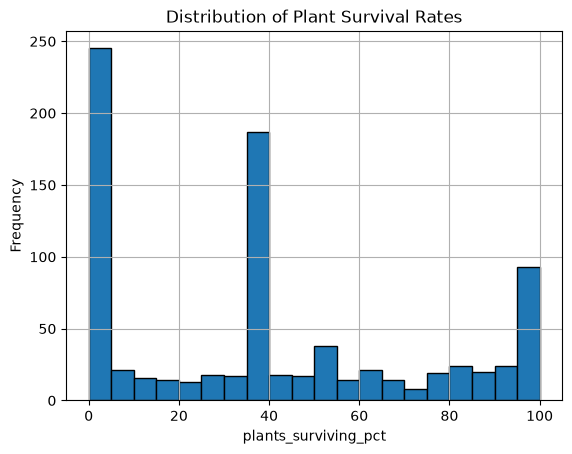

In [38]:
target_column = "plants_surviving_pct"

df[target_column].hist(bins=20, edgecolor="black")
plt.xlabel(f"{target_column}")
plt.ylabel("Frequency")
plt.title("Distribution of Plant Survival Rates")
plt.show()


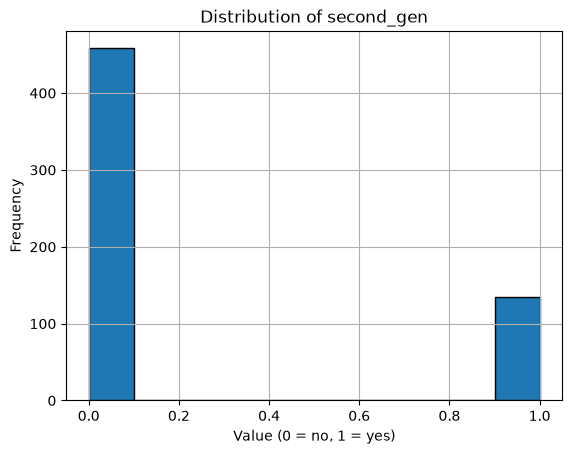

In [39]:
# import pandas as pd
# import matplotlib.pyplot as plt

# Replace "second_gen" with your column name
target_column = "second_gen"

dict_map = {
    "no": 0.0,
    "yes": 1.0
}

# Normalize strings, map known values, and turn unmatched values into NaN
values = df[target_column].astype("string").str.strip().str.lower()
numeric_values = values.map(dict_map)

# Plot the mapped values
numeric_values.dropna().hist(bins=10, edgecolor="black")
plt.xlabel("Value (0 = no, 1 = yes)")
plt.ylabel("Frequency")
plt.title(f"Distribution of {target_column}")
plt.show()


## 5.3 - PLOT: 'second_gen'

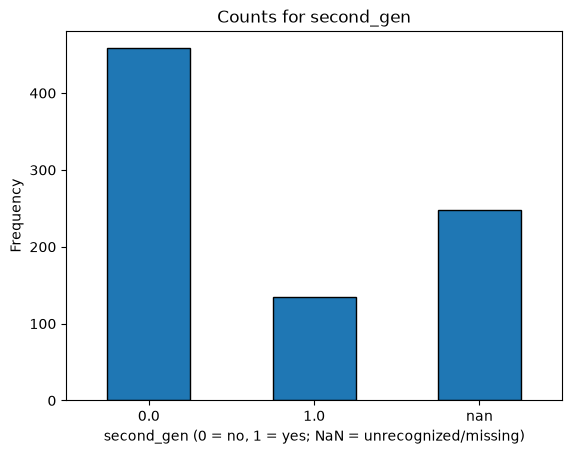

In [40]:
# import pandas as pd
# import matplotlib.pyplot as plt

target_column = "second_gen"
df_temp = df.copy()

dict_map = {"no": 0.0, "yes": 1.0}

# Normalize text; unrecognized values (including "missing" and "too_soon") become NaN
values = df_temp[target_column].astype("string").str.strip().str.lower()
df_temp[target_column] = values.map(dict_map)

df_temp[target_column].value_counts(dropna=False).sort_index().plot(
    kind="bar", edgecolor="black"
)
plt.xlabel("second_gen (0 = no, 1 = yes; NaN = unrecognized/missing)")
plt.ylabel("Frequency")
plt.title("Counts for second_gen")
plt.xticks(rotation=0)
plt.show()


## 5.4 - BONUS: EXPERIMENTAL DISTRIBUTION CHECK

Checks to review how closely a data series aligns with a statistical distribution

In [41]:
# TRY TO FIND A REASONABLE DISTRIBUTION TO DESCRIBE THE DATA
# import numpy as np
# from   scipy import stats

x = df["plants_surviving_pct"].dropna().astype(float).to_numpy()

candidates       =  {
                        "normal"     : stats.norm,
                        "lognormal"  : stats.lognorm,
                        "gamma"      : stats.gamma,
                        "weibull"    : stats.weibull_min,
                        "logistic"   : stats.logistic,
                        "student_t"  : stats.t,
                        "uniform"    : stats.uniform,
                        "triangular" : stats.triang,
                        "exponential": stats.expon,
                        "invgamma"   : stats.invgamma,
                        "fisk"       : stats.fisk,
                    }

results          = []

for name, dist in candidates.items():
    try:
        params         = dist.fit(x)
        log_likelihood = np.sum(dist.logpdf(x, *params))
        n_params       = len(params)
        aic            = 2 * n_params - 2 * log_likelihood
        results.append((name, aic, params))
    except (ValueError, FloatingPointError):
        pass

results.sort(key=lambda row: row[1])

print("=" * 80)
print("DISTRIBUTION\tAIC\t\t\tPARAMETERS")
print("=" * 80)
for name, aic, params in results:
    print(f"{name:10s}\tAIC= {aic:.2f}\t\t{params}")

print("=" * 80)
print("Lowest-AIC candidate:\t", results[0][0])
print("=" * 80)

C:\Users\duffl\anaconda3\envs\ml-zoomcamp\Lib\site-packages\scipy\stats\_continuous_distns.py:6941: RuntimeWarning: overflow encountered in divide
  return np.sum((1 + np.log(shifted/scale)/shape**2)/shifted)
C:\Users\duffl\anaconda3\envs\ml-zoomcamp\Lib\site-packages\numpy\_core\fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)


DISTRIBUTION	AIC			PARAMETERS
lognormal 	AIC= -306333.26		(np.float64(327.34955786162504), np.float64(-5e-324), np.float64(5.909817755828288e-83))
gamma     	AIC= -6273.81		(np.float64(0.24509959593152958), np.float64(-2.2336766936384963e-21), np.float64(29.787970170440794))
weibull   	AIC= -4625.04		(np.float64(0.5266193278799647), np.float64(-3.574792886562878e-27), np.float64(23.42013929992001))
fisk      	AIC= 527.42		(np.float64(0.6833126269384688), np.float64(-2.2817502294669993e-25), np.float64(2.5971348379520593))
invgamma  	AIC= 7551.62		(np.float64(0.3318428487538122), np.float64(-6.776133586927681e-16), np.float64(7.938309694138404e-16))
uniform   	AIC= 7749.90		(0.0, 100.0)
exponential	AIC= 7854.16		(0.0, 39.14045209580838)
triangular	AIC= 8268.90		(np.float64(0.9999999942918278), np.float64(-47.50916816639457), np.float64(147.5091715826582))
normal    	AIC= 8330.35		(np.float64(39.14045209580838), np.float64(34.16932243206861))
logistic  	AIC= 8391.15		(np.float64(37.00154

<Axes: xlabel='plants_surviving_pct', ylabel='Count'>

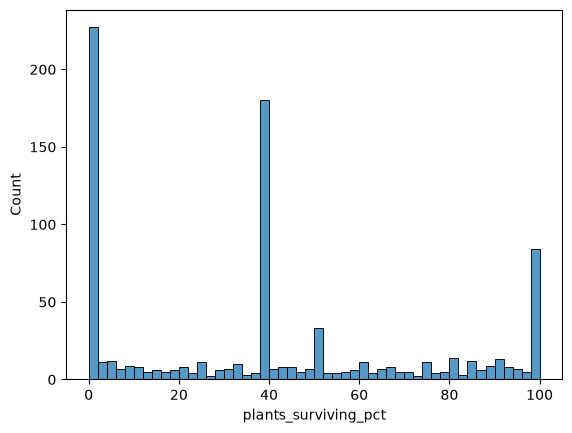

In [42]:

sns.histplot(df['plants_surviving_pct'], bins=50)


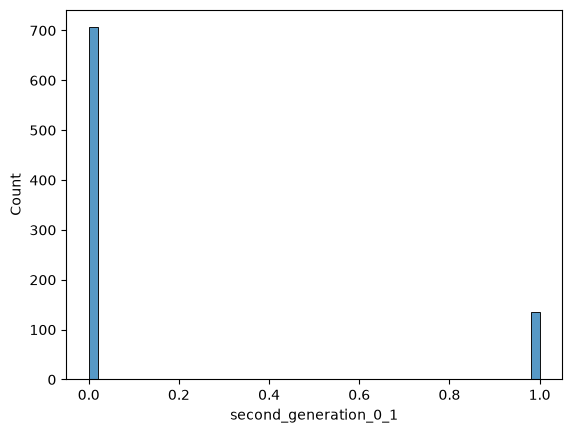

In [43]:
# PLOT 'second_generation_y_n_'

# CONVERT CATEGORICAL INFORMATION TO NUMERIC USING 'second_generation_0_1_'
dict_map = {
    'yes': 1,
    'no' : 0,
    'unk': 0,
}
source = df['second_gen'].astype('string').str.strip().str.lower()

df['second_generation_0_1'] = (
    source.map(dict_map)
          .fillna(0)
          .astype('int32')
)

# PLOT
sns.histplot(df['second_generation_0_1'], bins=50)

# DROP TEMP COLUMN USED TO CREATE THE PLOT
df.drop(columns=['second_generation_0_1'], inplace=True)

# 6.0 - PREPARE SPLIT DATASETS

In [44]:
# REVIEW COLUMNS
fn_view_col_value_status_table(df)

NON_MISSING	MISSING		%_MISSING	COLUMN
841		0		0.00%		lifeform
841		0		0.00%		state
841		0		0.00%		conservation_status
841		0		0.00%		habitat
841		0		0.00%		research
841		0		0.00%		mitigation
841		0		0.00%		translocation
841		0		0.00%		soil_prep
841		0		0.00%		pre_planting_burn
841		0		0.00%		pre_planting_slashing_or_weeding
841		0		0.00%		pre_site_prep
841		0		0.00%		exclosure_fence
841		0		0.00%		exclosure_cage
841		0		0.00%		tree_guard
841		0		0.00%		grazing_protection
841		0		0.00%		mulch
841		0		0.00%		watering
841		0		0.00%		burnt
841		0		0.00%		weeding
841		0		0.00%		plants_surviving_pct
841		0		0.00%		flowering_fruiting
841		0		0.00%		second_gen
841		0		0.00%		plants_surviving


## 6.1 -  ADJUST FOR MULTI-CLASS FEATURES

### 6.1.1 - INTRO

MULTI-CLASS records can either be fixed or deleted.  Given that we have not discussed how to applt one-hot encoding to a multi-class record, I propose an approach to address this.  I will not use this approach as it complicates the usability of the  prediction model as it forces the client to one-hot encode their data before using the web API.

### 6.1.1 - FIX MULTI-CLASS RECORDS

### 6.1.3 -  REMOVE MULTI-CLASS RECORDS

In [45]:
exclude_features_list   = ['translocation','burnt']

exclude_values          = r'introduction_augmentation_|introduction_reintroduction|planned_wildfire'

for feature in exclude_features_list:
    for status in exclude_values:
        df              = df.loc[
                                ~df[feature].str.contains(
                                    exclude_values, 
                                    na = False
                                )
                          ].copy()
    print(f"'{feature}' cleaned")


'translocation' cleaned
'burnt' cleaned


## 6.2 - MODEL TRAINING

### 6.2.1 - LOGISTIC REGRESSION

#### 6.2.1.1 - SPLIT THE DATASET

In [46]:
# SPLIT DATASET - LOGISTIC REGRESSION
# from sklearn.model_selection import train_test_split

# SET TARGET COLUMN
target_column          = 'plants_surviving'
model_seed             =  123456789
# df[target_column]      = (df["plants_surviving_pct"] > 0.0).astype(int)

df_full_train, df_test = train_test_split(
                            df,
                            test_size    = 0.2,  
                            random_state = model_seed,
                            stratify     = df[target_column]
                        )
df_train, df_val       = train_test_split(
                            df_full_train, 
                            test_size    = 0.25, 
                            random_state = model_seed,
                            stratify     = df_full_train[target_column]
                        )

# RESET INDEX 
df_train               = df_train.reset_index(drop=True)
df_val                 = df_val.reset_index(drop=True)
df_test                = df_test.reset_index(drop=True)

# CREATE TARGET VECTOR
y_train                = (df_train[target_column]).astype('int').values
y_val                  = (df_val[target_column]).astype('int').values
y_test                 = (df_test[target_column]).astype('int').values

# DROP TARGET (plants_surviving) FROM THE FEATURE MATRIX AND DROP PROXY FOR TARGET (plants_surviving_pct)
for in_df in (df_train, df_val, df_test):
    in_df.drop(columns=[target_column, 'plants_surviving_pct'], inplace=True)
    
# CREATE TRAINING, VALIDATION, AND TEST DICTIONARIES
train_dicts            = df_train.fillna(0).to_dict(orient='records')
val_dicts              = df_val.fillna(0).to_dict(orient='records')
test_dicts             = df_test.fillna(0).to_dict(orient='records')

# CREATE VECTORIZER
dv                     = DictVectorizer(sparse=True)

# CREATE FEATURE MATRIX
X_train                = dv.fit_transform(train_dicts)
X_val                  = dv.transform(val_dicts)
X_test                 = dv.transform(test_dicts)


# DEBUG  - 'y_test' DOES NOT STORE BOTH CASES
fn_view_column_value_counts(pd.DataFrame(y_train))
fn_view_column_value_counts(pd.DataFrame(y_val))
fn_view_column_value_counts(pd.DataFrame(y_test))



0
COUNT		FREQUENCY	VALUE
321		64.33%		1
178		35.67%		0

0
COUNT		FREQUENCY	VALUE
107		64.07%		1
60		35.93%		0

0
COUNT		FREQUENCY	VALUE
107		64.07%		1
60		35.93%		0


In [47]:
# DEBUG
train_names = set(dv.get_feature_names_out())  # vectorizer used for training

#### 6.2.1.2 - MAKE THE MODEL

In [48]:
# from sklearn.linear_model import LogisticRegression

model            =  LogisticRegression(
                        solver   = "lbfgs", 
                        max_iter = 1000
                    )
model.fit(X_train, y_train)


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

#### 6.2.1.3 - MAKE A PREDICTION

In [49]:
# CLASS 1: PLANTS SURVIVIE
y_pred           = model.predict_proba(X_val)[:, 1]
print(y_pred[:5])

[0.99673356 0.97543165 0.78824144 0.77354179 0.61341731]


#### 6.2.1.4 - RMSE VALIDATION

In [50]:
# from sklearn.metrics import root_mean_squared_error

predictions      = model.predict(X_val)
rmse             = root_mean_squared_error(y_val, predictions)

print("Validation RMSE:", rmse)


Validation RMSE: 0.3095292930136547


#### 6.2.1.5 - MODEL TUNING

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best C value: 0.01
Best logistic regression parameters: {'model__C': 0.01}
Best CV ROC AUC: 0.910


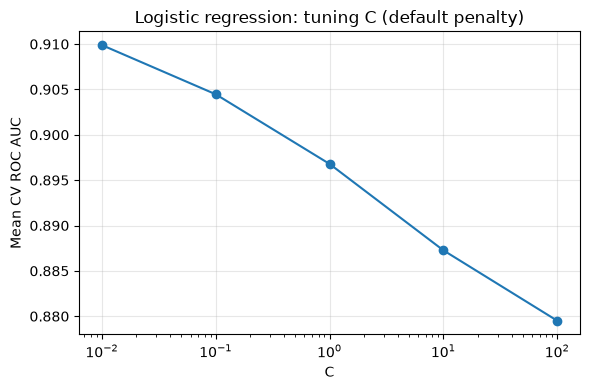

In [51]:
# import pandas                as pd
# import matplotlib.pyplot     as plt

# from sklearn.model_selection import GridSearchCV, StratifiedKFold
# from sklearn.pipeline        import Pipeline
# from sklearn.preprocessing   import StandardScaler
# from sklearn.linear_model    import LogisticRegression

cv               =  StratifiedKFold(
                        n_splits     = 5, 
                        shuffle      = True, 
                        random_state = 42
                    )

lr_pipeline      = Pipeline(
                        [
                            ("scale",   StandardScaler(
                                            with_mean=False
                                        )
                            ),
                            ("model",   LogisticRegression(
                                            solver       = "lbfgs",
                                            max_iter     = 5000,
                                            random_state = 42,
                                        )
                            ),
                        ]
                    )

param_grid       =  {
                        "model__C": [0.01, 0.1, 1, 10, 100],
                    }

lr_search        =  GridSearchCV(
                        estimator  = lr_pipeline,
                        param_grid = param_grid,
                        scoring    = "roc_auc",
                        cv         = cv,
                        n_jobs     = -1,
                        refit      = True,
                        verbose    = 1,
                    )

lr_search.fit(X_train, y_train)

# Fit the grid search
lr_search.fit(X_train, y_train)

# Save and print the best C value
best_C = lr_search.best_params_["model__C"]
print(f"Best C value: {best_C}")



print("Best logistic regression parameters:", lr_search.best_params_)
print(f"Best CV ROC AUC: {lr_search.best_score_:.3f}")

# ============================================================
# PLOT THE MEAN CV ROC AUC FOR EACH VALUE OF EACH TUNED PARAMETER
# ============================================================
results = pd.DataFrame(lr_search.cv_results_)

summary = (
    results.groupby("param_model__C")["mean_test_score"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(6, 4))
plt.plot(summary["param_model__C"], summary["mean_test_score"], marker="o")
plt.xscale("log")
plt.title("Logistic regression: tuning C (default penalty)")
plt.xlabel("C")
plt.ylabel("Mean CV ROC AUC")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


#### 6.2.1.6 - REVIEW PARAMETER IMPORTANCE

#### 6.2.1.6 - FINALIZE THE MODEL 

In [52]:
model_final_lr =  Pipeline(
                [
                    ("scale",   StandardScaler(
                                    with_mean    = False
                                )
                    ),
                    ("model",   LogisticRegression(
                                    C            = 1,
                                    solver       = "lbfgs",
                                    max_iter     = 5000,
                                    random_state = 42,
                                )
                    ),
                ]
            )

# MAKE THE FINALIZED, TUNED MODEL 
model_final_lr.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,107
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


#### 6.2.1.6 - CONSIDER A SIMPLIFIED MODEL

In [53]:
# import numpy as np
# import pandas as pd 
# from sklearn.inspection import permutation_importance
# from sklearn.pipeline import Pipeline
# from sklearn.preprocessing import StandardScaler
# from sklearn.linear_model import LogisticRegression

# Permutation importance requires dense input in this setup.
X_val_for_importance = (
    X_val.toarray() if hasattr(X_val, "toarray") else X_val
)

# Calculate permutation importance
result           =  permutation_importance(
                        estimator=model_final_lr,
                        X=X_val_for_importance,
                        y=y_val,
                        scoring="roc_auc",
                        n_repeats=20,
                        random_state=42,
                        n_jobs=-1,
                    )

# Build the feature-importance table
feature_names    = (
                        list(X_val.columns)
                        if hasattr(X_val, "columns")
                        else [f"feature_{i}" for i in range(X_val.shape[1])]
                    )

importance       =  pd.DataFrame(
                        {
                            "feature_index": np.arange(X_val.shape[1]),
                            "feature": feature_names,
                            "importance_mean": result.importances_mean,
                            "importance_std": result.importances_std,
                        }
                    ).sort_values("importance_mean")

# Select candidate features to drop
low_mean_cutoff  = importance["importance_mean"].quantile(0.10)
low_std_cutoff   = importance["importance_std"].median()

drop_mask        =  (
                        (importance["importance_mean"] <= low_mean_cutoff)
                        & (importance["importance_std"] <= low_std_cutoff)
                    )

features_to_drop = importance.loc[drop_mask, "feature"].tolist()
drop_indices     = importance.loc[drop_mask, "feature_index"].to_numpy()

print("Candidate features to drop:", features_to_drop)

# Keep all columns except the candidates
keep_mask        = np.ones(X_train.shape[1], dtype=bool)
keep_mask[drop_indices] = False

def select_columns(X, mask):
    """Select columns from a DataFrame, sparse matrix, or NumPy array."""
    if hasattr(X, "iloc"):
        return X.iloc[:, mask]
    return X[:, mask]

X_train_reduced  = select_columns(X_train, keep_mask)
X_val_reduced    = select_columns(X_val, keep_mask)
X_test_reduced   = select_columns(X_test, keep_mask)

# Fit a new model on the reduced feature set
model_simplified_lr =  Pipeline(
                        [
                            ("scale", StandardScaler(with_mean=False)),
                            ("model", LogisticRegression(
                                C            = 1,  # replace with your selected C value
                                solver       = "lbfgs",
                                max_iter     = 5000,
                                random_state = 42,
                            )),
                        ]
                    )

model_simplified_lr.fit(X_train_reduced, y_train)


Candidate features to drop: ['feature_89', 'feature_30', 'feature_12', 'feature_78', 'feature_88', 'feature_106', 'feature_46']


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,100
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


#### 6.2.1.6 - EVALUATE THE SIMPLIFIED MODEL

In [54]:
# from sklearn.metrics import root_mean_squared_error

predictions      = model_simplified_lr.predict(X_val_reduced)
rmse             = root_mean_squared_error(y_val, predictions)

print("SIMPLIFIED MODEL VALIDATION RMSE:", rmse)

predictions      = model_simplified_lr.predict(X_test_reduced)
rmse             = root_mean_squared_error(y_test, predictions)

print("SIMPLIFIED MODEL TEST RMSE:", rmse)

SIMPLIFIED MODEL VALIDATION RMSE: 0.27900593430471243
SIMPLIFIED MODEL TEST RMSE: 0.3546103537603097


### 6.2.1 - DECISION TREE

#### 6.3.1.1 - MAKE THE BASE MODEL

In [55]:
# from sklearn.tree    import DecisionTreeClassifier
# from sklearn.metrics import roc_auc_score, classification_report

# Create and fit the decision tree
tree_model       =  DecisionTreeClassifier(
                        max_depth         = 5,              # adjust or tune this
                        min_samples_split = 2,
                        min_samples_leaf  = 1,
                        random_state      = model_seed,
                    )
tree_model.fit(X_train, y_train)

# Predict probabilities and class labels
tree_probs       = tree_model.predict_proba(X_test)[:, 1]
tree_preds       = tree_model.predict(X_test)

# Compare with your fitted logistic-regression model: lr
# lr_probs = lr.predict_proba(X_test)[:, 1]

print(f"Decision tree test ROC AUC:        {roc_auc_score(y_test, tree_probs):.3f}")
# print(f"Logistic regression test ROC AUC:  {roc_auc_score(y_test, lr_probs):.3f}")

print("\nDecision tree classification report:")
print(classification_report(y_test, tree_preds))


Decision tree test ROC AUC:        0.934

Decision tree classification report:
              precision    recall  f1-score   support

           0       0.72      0.87      0.79        60
           1       0.92      0.81      0.86       107

    accuracy                           0.83       167
   macro avg       0.82      0.84      0.82       167
weighted avg       0.85      0.83      0.83       167



#### 6.3.1.2 - MODEL TUNING

Fitting 5 folds for each of 96 candidates, totalling 480 fits


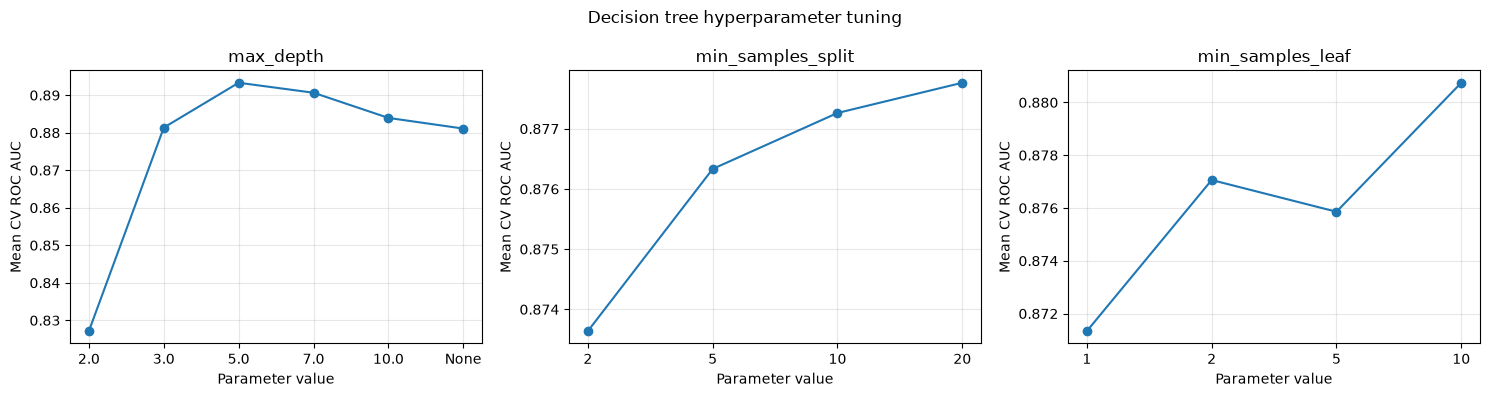

Best parameters: {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 20}
Best CV ROC AUC: 0.898
Test ROC AUC: 0.940
              precision    recall  f1-score   support

           0       0.73      0.88      0.80        60
           1       0.93      0.81      0.87       107

    accuracy                           0.84       167
   macro avg       0.83      0.85      0.83       167
weighted avg       0.85      0.84      0.84       167



In [56]:
# from sklearn.model_selection import GridSearchCV, StratifiedKFold
# from sklearn.tree            import DecisionTreeClassifier
# from sklearn.metrics         import roc_auc_score, classification_report

# ==============================================================================
# NEW MODEL TUNING CODE BLOCK #1 STARTS HERE 
# ==============================================================================
cv               =  StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# ==============================================================================
# NEW MODEL TUNING CODE BLOCK #1 ENDS HERE 
# ==============================================================================

tree             =  DecisionTreeClassifier(random_state=42)

param_grid       =  {
                        "max_depth"         : [2, 3, 5, 7, 10, None],
                        "min_samples_split" : [2, 5, 10, 20],
                        "min_samples_leaf"  : [1, 2, 5, 10],
                    }

tree_search      =  GridSearchCV(
                        estimator  = tree,
                        param_grid = param_grid,
                        scoring    = "roc_auc",
                        cv         = cv,
                        n_jobs     = -1,
                        refit      = True,
                        verbose    = 1,
                    )

tree_search.fit(X_train, y_train)

# ==============================================================================
# NEW MODEL TUNING CODE BLOCK #2 STARTS HERE 
# ==============================================================================
# import pandas as pd
# import matplotlib.pyplot as plt

# CREATE PLOTS TO EVALUATE HYPER-PARAMETER TUNING
results          =  pd.DataFrame(tree_search.cv_results_)

params           =  ["max_depth", "min_samples_split", "min_samples_leaf"]
fig, axes        =  plt.subplots(1, 3, figsize=(15, 4))

for ax, param in zip(axes, params):
    summary      =  (
                        results.groupby(f"param_{param}", dropna=False)["mean_test_score"]
                        .mean()
                        .reset_index()
                    )

    # Treat values as categories so that None is displayed correctly
    x_labels     =  summary[f"param_{param}"].map(
                        lambda value: "None" if pd.isna(value) else str(value)
                    )

    ax.plot(x_labels, summary["mean_test_score"], marker="o")
    ax.set_title(param)
    ax.set_xlabel("Parameter value")
    ax.set_ylabel("Mean CV ROC AUC")
    ax.grid(True, alpha=0.3)

plt.suptitle("Decision tree hyperparameter tuning")
plt.tight_layout()
plt.show()
# ==============================================================================
# NEW MODEL TUNING CODE BLOCK #2 ENDS HERE
# ==============================================================================

print("Best parameters:", tree_search.best_params_)
print(f"Best CV ROC AUC: {tree_search.best_score_:.3f}")

# Evaluate the tuned tree on the held-out test set
best_tree        = tree_search.best_estimator_
tree_probs       = best_tree.predict_proba(X_test)[:, 1]
tree_preds       = best_tree.predict(X_test)

print(f"Test ROC AUC: {roc_auc_score(y_test, tree_probs):.3f}")
print(classification_report(y_test, tree_preds))


#### 6.3.1.3 - FINALIZE THE TUNED MODEL

In [57]:
# from sklearn.tree import DecisionTreeClassifier

final_tree       =  DecisionTreeClassifier(
                        max_depth         = 5,            # replace with your tuned value
                        min_samples_split = 10,   # replace with your tuned value
                        min_samples_leaf  = 2,     # replace with your tuned value
                        random_state      = model_seed,
                    )

final_tree.fit(X_train, y_train)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",123456789
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sa

#### 6.3.1.4 - CONSIDER A SIMPLIFIED MODEL

In [58]:
# import numpy as np
# import pandas as pd
# from sklearn.inspection import permutation_importance
# from sklearn.metrics import accuracy_score
# from sklearn.tree import DecisionTreeClassifier
# from sklearn.feature_extraction import DictVectorizer

# ============================================================
# STEP 1 — CREATE A LIST OF ORIGINAL FEATURE NAMES
#          USE THIS LIST TO CREATE A NEW VECTORIZER IF 
#          FEATURES ARE EVENTUALLY DROPPED
# ============================================================
dv_feature_names = list(dv.get_feature_names_out())

# ============================================================
# STEP 2 — FIT THE BASELINE TREE AND MEASURE FEATURE IMPORTANCE
# ============================================================

# Refit the best tree found during tuning.
# If you don't have tree_search, replace tree_search.best_params_
# with your chosen parameters, for example:
# tree_params = {
#     "max_depth": 5,
#     "min_samples_split": 10,
#     "min_samples_leaf": 2,
# }
tree_params      =  tree_search.best_params_

baseline_tree    =  DecisionTreeClassifier(
                        **tree_params,
                        random_state = model_seed,
                    )
baseline_tree.fit(X_train, y_train)

# Densify sparse validation data if needed for permutation_importance.
X_val_for_importance = (
                        X_val.toarray() if hasattr(X_val, "toarray") else X_val
                    )

importance_result = permutation_importance(
                        estimator    = baseline_tree,
                        X            = X_val_for_importance,
                        y            = y_val,
                        scoring      = "accuracy",
                        n_repeats    = 20,
                        random_state = model_seed,
                        n_jobs       = -1,
                    )

feature_names    =  (
                        list(X_val.columns)
                        if hasattr(X_val, "columns")
                        else [f"feature_{i}" for i in range(X_val.shape[1])]
                    )

importance       = pd.DataFrame(
                        {
                            "feature_index": np.arange(X_val.shape[1]),
                            "feature": feature_names,
                            "importance_mean": importance_result.importances_mean,
                            "importance_std": importance_result.importances_std,
                        }
                    ).sort_values("importance_mean")

print("Feature importance:")
print(importance.to_string(index=False))


# ============================================================
# STEP 3 — SELECT CANDIDATE FEATURES AND DROP THEM
# ============================================================

# Candidate features: bottom 10% by mean importance,
# with importance variability below the median.
low_mean_cutoff  = importance["importance_mean"].quantile(0.10)
low_std_cutoff   = importance["importance_std"].median()

candidate_mask   = (
                        (importance["importance_mean"] <= low_mean_cutoff)
                        & (importance["importance_std"] <= low_std_cutoff)
                    )

features_to_drop = importance.loc[candidate_mask, "feature"].tolist()



drop_names       = set(features_to_drop)
kept_names       =  [
                        name for name in dv.get_feature_names_out()
                        if name not in drop_names
                    ]
simplified_vocabulary = {name: i for i, name in enumerate(kept_names)}
from sklearn.feature_extraction import DictVectorizer
# Fit on raw dictionaries first
simplified_dv    = DictVectorizer()
simplified_dv.fit(train_dicts)
# Keep only the selected feature names, with contiguous column indices
kept_names       =  [
                        name for name in dv.get_feature_names_out()
                        if name not in set(features_to_drop)
                    ]

simplified_dv.vocabulary_ = {name: i for i, name in enumerate(kept_names)}
# Transform raw dictionaries using the reduced vocabulary
X_train_reduced = simplified_dv.transform(train_dicts)
X_val_reduced   = simplified_dv.transform(val_dicts)
print(f"Features retained: {X_train_reduced.shape[1]}")
print(f"Features retained: {len(kept_names)} of {len(feature_names)}")

drop_indices     = importance.loc[candidate_mask, "feature_index"].to_numpy()

def select_columns(X, mask):
    """Select columns from a DataFrame, sparse matrix, or NumPy array."""
    if hasattr(X, "iloc"):
        return X.iloc[:, mask]
    return X[:, mask]

X_train_reduced  = simplified_dv.transform(train_dicts)
X_val_reduced    = simplified_dv.transform(val_dicts)
X_test_reduced   = simplified_dv.transform(test_dicts)

print("Train shape:", X_train_reduced.shape)
print("Test shape: ", X_test_reduced.shape)

print("\nCandidate features to drop:")
print(features_to_drop)
print(f"Features retained: {keep_mask.sum()} of {len(keep_mask)}")


# ============================================================
# STEP 4 — REFIT THE SIMPLIFIED TREE AND COMPARE ACCURACY
# ============================================================

model_simplified_tree   = DecisionTreeClassifier(
                              **tree_params,
                              random_state = model_seed,
                          )
model_simplified_tree.fit(X_train_reduced, y_train)

baseline_val_accuracy   = accuracy_score(
                              y_val,
                              baseline_tree.predict(X_val),
                          )
simplified_val_accuracy = accuracy_score(
                            y_val,
                            model_simplified_tree.predict(X_val_reduced),
                          )

print(f"\nBaseline validation accuracy:   {baseline_val_accuracy:.3f}")
print(f"Simplified validation accuracy: {simplified_val_accuracy:.3f}")
print(f"Accuracy change:                {simplified_val_accuracy - baseline_val_accuracy:+.3f}")


Feature importance:
 feature_index     feature  importance_mean  importance_std
            23  feature_23        -0.012575        0.005649
            31  feature_31        -0.005988        0.008677
             0   feature_0         0.000000        0.000000
             2   feature_2         0.000000        0.000000
             6   feature_6         0.000000        0.000000
             5   feature_5         0.000000        0.000000
             3   feature_3         0.000000        0.000000
             4   feature_4         0.000000        0.000000
            15  feature_15         0.000000        0.000000
             9   feature_9         0.000000        0.000000
            10  feature_10         0.000000        0.000000
            12  feature_12         0.000000        0.000000
            14  feature_14         0.000000        0.000000
            18  feature_18         0.000000        0.000000
             7   feature_7         0.000000        0.000000
             8   fea

#### 6.3.1.5 - FINALIZE THE SIMPLIFIED MODEL

In [59]:
# from sklearn.tree import DecisionTreeClassifier

# RECREATE DICT VECTORIZER
# df


model_final_tree =  DecisionTreeClassifier(
                        max_depth         = 5,    # replace with your tuned value
                        min_samples_split = 10,   # replace with your tuned value
                        min_samples_leaf  = 2,    # replace with your tuned value
                        random_state      = model_seed,
                    )

model_final_tree.fit(X_train_reduced, y_train)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",123456789
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sa

### 6.2.3 - MODEL TUNING WITH 'xgboost'

In [60]:
# ============================================================
# IMPORTS
# ============================================================
# from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
# from sklearn.pipeline        import Pipeline
# from sklearn.preprocessing   import StandardScaler
# from sklearn.linear_model    import LogisticRegression
# from sklearn.metrics         import roc_auc_score, classification_report
# from xgboost                 import XGBClassifier
# import joblib

# ============================================================
# CROSS-VALIDATION SETUP
# ============================================================
cv               =  StratifiedKFold(
                        n_splits     = 5, 
                        shuffle      = True, 
                        random_state = model_seed
                    )

# ============================================================
# XGBOOST: DEFINE MODEL AND HYPERPARAMETER SEARCH
# ============================================================
xgb              = XGBClassifier(
                       objective    = "binary:logistic",
                       eval_metric  = "logloss",
                       random_state = model_seed,
                       n_jobs       = 1  # avoid oversubscribing CPUs while GridSearchCV runs in parallel
                    )

param_grid       = {
                        "learning_rate": [0.01, 0.03, 0.1],  # eta
                        "max_depth": [3, 5, 7],
                        "min_child_weight": [1, 3, 5],
                    }

xgb_search       = GridSearchCV(
                        estimator  = xgb,
                        param_grid = param_grid,
                        scoring    = "roc_auc",
                        cv         = cv,
                        n_jobs     = -1,
                        refit      = True,
                        verbose    = 1
                    )

# ============================================================
# FIT XGBOOST GRID SEARCH
# ============================================================
xgb_search.fit(X_train_reduced, y_train)

# ============================================================
# FIT LOGISTIC-REGRESSION BASELINE
# ============================================================
lr               = Pipeline([
                        ("scale", StandardScaler(with_mean=False)),  # supports sparse features
                        ("model", LogisticRegression(max_iter=2000)),
                    ])
lr.fit(X_train_reduced, y_train)

# ============================================================
# EVALUATE MODELS ON THE HELD-OUT TEST SET
# ============================================================
xgb_probs        = xgb_search.best_estimator_.predict_proba(X_test_reduced)[:, 1]
lr_probs         = lr.predict_proba(X_test_reduced)[:, 1]
xgb_preds        = xgb_search.best_estimator_.predict(X_test_reduced)

print(f"Best XGBoost parameters:          {xgb_search.best_params_}")
print(f"Best XGBoost CV ROC AUC:          {xgb_search.best_score_:.3f}")
print(f"XGBoost test ROC AUC:             {roc_auc_score(y_test, xgb_probs):.3f}")
print(f"Logistic regression test ROC AUC: {roc_auc_score(y_test, lr_probs):.3f}")

print("\nXGBoost classification report:")
print(classification_report(y_test, xgb_preds))

# ============================================================
# FINALIZE AND SAVE THE SELECTED MODEL
# ============================================================
# With refit=True, GridSearchCV has already refit the best estimator
# on all of X_train and y_train.
final_model      = xgb_search.best_estimator_

joblib.dump(final_model, "final_xgb_model.joblib")
print("\nFinal model saved as 'final_xgb_model.joblib'.")


Fitting 5 folds for each of 27 candidates, totalling 135 fits
Best XGBoost parameters:          {'learning_rate': 0.03, 'max_depth': 7, 'min_child_weight': 1}
Best XGBoost CV ROC AUC:          0.929
XGBoost test ROC AUC:             0.958
Logistic regression test ROC AUC: 0.944

XGBoost classification report:
              precision    recall  f1-score   support

           0       0.80      0.85      0.82        60
           1       0.91      0.88      0.90       107

    accuracy                           0.87       167
   macro avg       0.85      0.86      0.86       167
weighted avg       0.87      0.87      0.87       167


Final model saved as 'final_xgb_model.joblib'.


# 7.0 - PREPARE BINARY

## 7.1 - TEST A MESSAGE

In [61]:
# ============================================================
#  CREATE A TEST DATAPOINT AS A DICTIONARY
# ============================================================
row              =  X_test.getrow(10)
feature_names    =  simplified_dv.get_feature_names_out()

X_test_datapoint =  {
                        feature_names[i]: float(value)
                        for i, value in zip(row.indices, row.data)
                    }
print(X_test_datapoint)



{'burnt=unburnt': 1.0, 'conservation_status=not_listed': 1.0, 'exclosure_cage=no': 1.0, 'exclosure_fence=no': 1.0, 'flowering_fruiting=no': 1.0, 'grazing_protection=no': 1.0, 'habitat=coastal_heath': 1.0, 'lifeform=shrub': 1.0, 'mitigation=yes': 1.0, 'mulch=no': 1.0, 'pre_planting_burn=no': 1.0, 'pre_planting_slashing_or_weeding=yes': 1.0, 'pre_site_prep=yes': 1.0, 'research=yes': 1.0, 'second_gen=no': 1.0, 'soil_prep=yes': 1.0, 'state=qld': 1.0, 'translocation=introduction': 1.0, 'tree_guard=no': 1.0, 'watering=yes': 1.0, 'weeding=yes': 1.0}


## 7.2 - MAKE A BINARY

In [62]:
# ============================================================
# EXPORT MODEL AS A PIPELINE BINARY 
# ============================================================
# from   pathlib import Path
# import pickle
# from   sklearn.pipeline import Pipeline

# Combine the DictVectorizer and your trained model into a pipeline
model_pipeline   =  Pipeline(
                        [
                            ('vectorizer', simplified_dv),
                            ('model',      final_model)
                        ]
                    )

output_file = f'model_C={best_C}.bin'  # 'best_C' is created in #6.2.1.5

with open(output_file, 'wb') as f_out:
    pickle.dump(model_pipeline, f_out)

print(f"Model pipeline binary saved to '{output_file}'")


Model pipeline binary saved to 'model_C=0.01.bin'


## 7.3 - USE THE BINARY

In [66]:
# from pathlib import Path
# import pickle

# ============================================================
# LOAD THE TRAINED PIPELINE
# ============================================================
MODEL_PATH = Path(output_file)  # or Path(f"model_C={best_C}.bin")

with MODEL_PATH.open("rb") as f_in:
    pipeline = pickle.load(f_in)

# ============================================================
# MAKE A PREDICTION
# ============================================================
probability = pipeline.predict_proba([X_test_datapoint])[0, 1]
prediction = int(probability >= 0.5)

print("prediction\t", prediction)
print("probability\t", probability)


prediction	 0
probability	 0.11508376


# 8.0 - BUILD WEB SERVICE WITH 'FastAPI' AND 'uvicorn'

## 8.1 - CREATE `predict.py`
`predict.py` is a script that creates a localhost (IP: 0.0.0.0) web service instance running in `uvicorn`\
The web service responds to an HTTP POST commands that send JSON formatted plant features defined in the Austrailian Plants Translocation Database \
\
The data frm the Australian Plants Translocation Database is messy:
1. The web service **sanitizes** the feature list by dropping any features that the model does not need.
2. The sanitation process also inserts any missing key/value pairs that the model requires
\
Once sanitized, the web service **enriches** JSON features
1. cleaning messy values
2. mapping free-text values to standard values
3. collapsing similar categorical feature values together.

The enriched JSON is validated using `pydantic`\
\
The validated JSON is passed to the prediction model

In [64]:
# DEBUG 
print("NOTE:\tThe name of the file holding the prediction model needs to be hard-coded into the `MODEL_PATH` variable in the `predict.py` script")
print("\tModel:\t", output_file,"\r\n")  # model_C=0.01.bin


NOTE:	The name of the file holding the prediction model needs to be hard-coded into the `MODEL_PATH` variable in the `predict.py` script
	Model:	 model_C=0.01.bin 



## 8.2 - START THE WEB SERVICE


**STARTING THE WEB SERVICE**
  1. Open a terminal in the python environment 
  2. Navigate to the project root directory (/ml-zoomcamp-homework/07_midterm_project_plants/plants_package>) 
  3. Run uv init to create the pyproject.toml file
     `uvicorn predict:app --host 0.0.0.0 --port 9696 --reload                            `

**NOTES**
  1. CTL+C does not work to stop the web service on Windows 11
  2. Attempting to stop uvicorn when using port 9696 manually does not work even if you run `netstat -ano | findstr :9696` in powershell to identify all process IDs associated with port 9696 before tring to kill those processes using `Stop-Process -Id 18000 -Force` where 18000 woiuld represent a process ID you are trying to kill.
  3. The only way I've been able to stop the web service is to fully reboot the computer

## 8.3 - TEST THE WEB SERVICE

### 8.3.1 - TESTING FROM JUPYTER

In [65]:
# ============================================================
# TEST THE MODEL 
# ============================================================
# import requests
# import json

url              = 'http://localhost:9696/predict'

observation      = {
                      "status_summary"                       : "finalised",
                      "conservation_status_epbc_"            : "en",
                      "broad_habitat_group"                  : "rainforest",
                      "translocation_type"                   : "introduction",
                      "soil_preparation_y_n_"                : "y_slow_release_fertilizer",
                      "pre_planting_burn_y_n_"               : "n",
                      "pre_planting_slashing_or_weeding_y_n_": "y",
                      "pre_site_preparation_all_"            : "1.0",
                      "herbivore_exclosure_fence_y_n_"       : "y",
                      "herbivore_exclosure_cages_y_n_"       : "n",
                      "tree_guards_y_n_"                     : "n",
                      "grazing_protection_all_"              : "1.0",
                      "mulching_y_n_"                        : "n",
                      "watering_all_"                        : "0.0",
                      "burnt_0_unburnt_1_planned_2_wildfire_": "0",
                      "weeding_includes_exotic_and_native_competitors_number_of_times_or_y_n_": "4_years",
                      "reproductive_flowering_fruiting_y_n_" : "n",
                      "lifeform"                             : "tree",
                      "state"                                : "nsw",
                      "mitigation"                           : "y",
                      "second_gen"                           : "0",
                      "research"                             : "previous_translocation"
                    }

response         = requests.post(url, json=observation, timeout=30)
response.raise_for_status()

result           = response.json()
print(json.dumps(result, indent=2))


{
  "prediction_probability": 0.9270420670509338,
  "prediction": 1
}


### 8.3.2 - TESTING FROM POWERSHELL

# 9.0 -PREPARE FOR A PACKAGE BUILD

## 9.1 - ORGANIZE FILES

## 9.2 - UPDATE FILES TO REFLECT THE NEW DIRECTORY STRUCTURE

## 9.3 - CREATE 'pyproject.tom'

1. Open a terminal in the python environment
2. Navigate to the project root directory (/ml-zoomcamp-homework/plants_package)
3. Run `uv init` to create the `pyproject.toml` file
4. Add dependencies to the toml file with this command\
   `uv add pandas scikit-learn joblib pathlib typing uvicorn fastapi pydantic requests xgboost`
5. Modify the following entries in the toml file \
   a. `name` \
   b. `description` \
   c. `authors` 
6. Save the toml file

NOTE: To run a python file or application inside of this virtual environment, prefix your command with a call to `uv run` \
\
   EXAMPLE:\t`uv run uvicorn predict:app --host 0.0.0.0 --port 9696 --reload`

## 9.4 - RUNNING THE APPLICATION IN THE NEW ENVIRONMENT

INSTRUCTIONS
  1. open a python terminal
  2. navigate to the directory where midterm projects are stored
  3. start the web service inside of the new environment
      `uv run uvicorn predict:app --host 0.0.0.0 --port 9696 --reload`

NOTE\
  To run a command stored in a `uv` environment, prefix your command instruction with `uv run`
                                                   

## 9.5 - TESTING THE APP IN 'uv' ENVIRONMENT 

# 10.0 - CREATE DOCKERFILE

## 10.1 - CREATE 'Dockerfile'

## 10.2 - CREATE DOCKER IMAGE

1. OPEN A TERMINAL AND NAVIGATE TO THE PROJECT DIRECTORY: \
        `/07_midterm_project_plants/plants_package` 
2. CREATE `uv` LOCK FILE BY RUNNING THE FOLLOWING COMMAND FROM YOUR TERMINAL
        `uv lock`
3. ENSURE THAT YOUR `Dockerfile` FILE IS IN THIS DIRECTORY
        `/07_midterm_project_plants/plants_package`
4. CONFIRM THAT YOUR LOCAK DOCKER ENGINE IS RUNNING \
  YOU MAY NEED TO START THE DOCKER APP MANUALLY \
        `[WINDOWS] ==> START ==> 'Docker Desktop'`
6. CREATE THE DOCKER IMAGE WITH THIS TERMINAL COMMAND
        `docker build -t plants_app .`
   NOTE: THE PERIOD AFTER `plants_app` IS IMPORTANT AS IT TELLS DOCKER THAT YOU ARE ALREADY IN THE PROJECT DIRECTORY

SWITCH DESCRIPTION
    `build`            TELLS DOCKER TO CREATE A CONTAINER IMAGE
    `-t plants_app`    TELLS DOCKER TO NAME THE CONTAINER IMAGE 'plants_app'

## 10.3 - START THE DOCKER CONTAINER 

1. OPEN A TERMINAL AND MAKE SURE YOU ARE IN THE PROJECTS DIRECTORY
2. RUN THE FOLLOWING COMMAND
        `docker run -it -p 9696:9696 plants_app:latest`

SWITCH DESCRIPTION \
    `run`               TELLS DOCKER TO START THE CONTAINER IMAGE \
    `-it`               TELLS DOCKER TO KEEP THE IMAGE ATTACHED TO THIS TERMINAL SO IT CAN BE STOPPED \
    `-p 9696:9696`      PUBLISH THE CONTAINER PORT AS 9696 (PARAMETER BEFORE THE ':') AND MAKE THIS PORT ACCESSIBLE TO THE HOST COMPUTER THROUGH PORT 9696 (PARAMETER AFTER THE ':') \ 
    `plants_app:latest` IMAGE NAME (plants_app) AND TAG (latest)

# 11.0 - DEPLOY TO fly.io

## 11.1 - FLY SETUP

Sign me up for Fly.io and deploy my first app. Fly.io runs apps on Machines: fast-booting VMs that start in about a second, run close to users in regions around the world, and stop when idle so I only pay for what I use.

1. Install flyctl:
   [BASH] `curl -L https://fly.io/install.sh | sh` \
   [POWERSHELL] `iwr https://fly.io/install.ps1 -useb | iex` \

```
POWERSHELL CAPTURE - INSTALLING FLY 
PS C:\Users\duffl\anaconda3\_CT161_GitHub_Repos\ml-zoomcamp-homework\07_midterm_project_plants\plants_package> iwr https://fly.io/install.ps1 -useb | iex
Downloading flyctl...
flyctl was installed successfully to C:\Users\duffl\.fly\bin\flyctl.exe
Restart your shell, then run 'flyctl --help' to get started
PS C:\Users\duffl\anaconda3\_CT161_GitHub_Repos\ml-zoomcamp-homework\07_midterm_project_plants\plants_package> 
```


2. Create my Fly.io account. This opens the sign-up page in my browser, where I can use my email address, Google account, or GitHub account. It waits until I approve, so run it in the background:
   fly auth signup
3. From inside my project source directory, launch my app. This detects my framework, generates a Dockerfile and fly.toml if needed, and deploys it to Machines:
   fly launch
4. Check that my Machines are running:
   fly status
5. Open my app in the browser, and check that it loads:
   fly apps open

If `fly auth signup` can't open a browser, it prints a link. Show me the link so I can open it, sign up, and approve. Keep that same command running: each run makes a new link, and only the one I approve finishes. If it stopped, ask me for the code the page shows after I approve, and run `fly auth login --code <code>`.

If I don't have a project yet, run a Machine directly from a public image instead. App names are unique across Fly.io, so let flyctl pick one, and use the name it prints in place of <app-name>. A Machine started this way has no public IP address, so add one before opening the app:
   fly apps create --generate-name
   fly machine run nginx --app <app-name> --port 80:80/tcp:http --port 443:80/tcp:http:tls
   fly ips allocate-v4 --shared --app <app-name>
   fly ips allocate-v6 --app <app-name>
   fly apps open --app <app-name>
```

To make future changes live, run `fly deploy` from the project directory.

Quickstart: https://fly.io/docs/getting-started/launch/
Machines docs: https://fly.io/docs/machines/


1. OPEN A TERMINAL AND MAKE SURE YOU ARE AT THE PROJECT ROOT DIRECTORY \
        `C:\Users\duffl\anaconda3\_CT161_GitHub_Repos\ml-zoomcamp-homework\07_midterm_project_plants\plants_package`
        NOTE: YOU WILL KNOW THAT YOU ARE IN THE PROJECT ROOT DIRECTORY WHEN YOU SEE THE FOLLOWING FILES
            * Dockerfile
            * pyproject.toml
2. RUN `fly auth signup` FROM THE TERMINAL AND FOLLOW THE PROMPTS TO AUTHENTICATE WITH GitHub, Google, ETC.
3. RUN `fly launch` AND ALLOW fly.io TO CREATE A `fly.toml` FILE
4. RUN `fly launch` TO UPLOAD THE DOCKER IMAGE, AND LAUNCH THE APPLICATION
        NOTE: YOU WILL RECEIVE FEEDBACK TELLING YOU THE URL WHERE YOUR APP MAY BE FOUND
            

## 11.3 - STARTING AND STOPING THE fly.io WEB SERVICE

**START**
1. OPEN A TERMINAL AND NAVIGATE TO YOUR PROJECT DIRECTORY
2. START AN EXISTING fly.io SERVICE WITH `fly deploy`
3. DO NOT CLOSE THIS TERMINAL

**STOP**
1. FROM THE TERMINAL USED TO LAUNCH THE fly.io WEBSERVICE, TYPE 'CTRL+C'

**DESTROYING fly.io MACHINE**
1. When fly.io deploys an app, it provides a URL to a management console in the terminal where you launched the app.  You can review fly.io logs for troubleshooting purposes here and also destroy fly.io machines to prevent application storage and utilization charges. 

## 11.4 - VIDEO OF THE APP DEPLOYED THROUGH fly.io

https://drive.google.com/file/d/15hliHKk76iawayqZHN4PUYxMd9COxD5s/view?usp=drive_link